## Deep Learning phase: Sentiment Classification using LSTM.

We'll build this ourselves in PyTorch, step by step.

Our implementation will have these stages:
1. Text tokenization and vocabulary creation.
2. Convert text into numerical sequences.
3. Padding and PyTorch Dataset/DataLoader.
4. Build the Embedding + LSTM model.
5. Train using GPU where available.
6. Evaluate, tune, and compare against classical ML.
7. Analyse overfitting and performance across review sources.

In [1]:
from pathlib import Path
import re
from collections import Counter

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

# Locate project directory
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data/processed/sentiment/train.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent.parent

DATA_DIR = PROJECT_ROOT / "data/processed/sentiment"

# Load datasets
train_df = pd.read_csv(DATA_DIR / "train.csv")
validation_df = pd.read_csv(DATA_DIR / "validation.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

# Check PyTorch environment
print("\nPyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Training: (1920, 5)
Validation: (480, 5)
Test: (600, 5)

PyTorch version: 2.14.1+cu132
CUDA available: True
Selected device: cuda
GPU: NVIDIA GeForce RTX 3080 Laptop GPU


## Step 2 — Tokenization and vocabulary creation

Before a neural network can process text, we must convert words into numerical IDs.

In [2]:
TOKEN_PATTERN = re.compile(r"\b\w+(?:['']\w+)?\b")

def tokenize(text):
    text = str(text).lower()
    tokens = TOKEN_PATTERN.findall(text)
    return tokens

In [3]:
sample_test = "This movie wasn't good, but the acting was excellent!"

print(tokenize(sample_test))

['this', 'movie', "wasn't", 'good', 'but', 'the', 'acting', 'was', 'excellent']


### Build the vocabulary using training data

In [4]:
# Minimum frequency required for a word to enter the vocabulary
MIN_FREQ = 2

# Count tokens from training sentences only
token_counts = Counter()

for text in train_df["text"]:
    token_counts.update(tokenize(text))

# Reserve special token IDs
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"


vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}



# Sort by descending frequency, then alphabetically for deterministic IDs

sorted_tokens = sorted(
    token_counts.items(),
    key = lambda item: (-item[1], item[0])
)


for token, count in sorted_tokens:
    if count >= MIN_FREQ:
        vocab[token] = len(vocab)


### Inspect the vocabulary

In [5]:
print("Total token occurrences:", sum(token_counts.values()))
print("Unique tokens before filtering:", len(token_counts))
print("Vocabulary size:", len(vocab))

print("\nFirst 20 vocabulary entries:")
print(list(vocab.items())[:20])

Total token occurrences: 22736
Unique tokens before filtering: 4031
Vocabulary size: 1619

First 20 vocabulary entries:
[('<PAD>', 0), ('<UNK>', 1), ('the', 2), ('and', 3), ('i', 4), ('a', 5), ('is', 6), ('it', 7), ('of', 8), ('this', 9), ('to', 10), ('was', 11), ('in', 12), ('for', 13), ('that', 14), ('not', 15), ('with', 16), ('on', 17), ('very', 18), ('my', 19)]


### Verify vocabulary filtering

In [6]:
print("MIN_FREQ:", MIN_FREQ)

print("Tokens appearing once:",
      sum(count == 1 for count in token_counts.values()))

print("Tokens appearing fewer than MIN_FREQ:",
      sum(count < MIN_FREQ for count in token_counts.values()))

print("Minimum token frequency:",
      min(token_counts.values()))

print("Actual vocabulary tokens:", len(vocab) - 2)

MIN_FREQ: 2
Tokens appearing once: 2414
Tokens appearing fewer than MIN_FREQ: 2414
Minimum token frequency: 1
Actual vocabulary tokens: 1617


In [7]:
print("Unique tokens:", len(token_counts))
print("Filtered tokens:", sum(count < MIN_FREQ for count in token_counts.values()))
print("Final vocabulary size:", len(vocab))
print("Actual vocabulary tokens:", len(vocab) - 2)

Unique tokens: 4031
Filtered tokens: 2414
Final vocabulary size: 1619
Actual vocabulary tokens: 1617


## Step 3 — Text encoding

### Write the encoding function

In [8]:
def encode_text(text, vocab):
    tokens = tokenize(text)

    token_ids = [
        vocab.get(token, vocab[UNK_TOKEN])
        for token in tokens
    ]

    return token_ids

In [9]:
sample_text = "This movie was really good"

encoded_sample = encode_text(sample_text, vocab)

print("Original text:", sample_text)
print("Tokens:", tokenize(sample_text))
print("Encoded sequence:", encoded_sample)

Original text: This movie was really good
Tokens: ['this', 'movie', 'was', 'really', 'good']
Encoded sequence: [9, 24, 11, 44, 20]


### Encode our datasets

In [10]:
X_train_sequences = [
    encode_text(text, vocab)
    for text in train_df["text"]
]

X_val_sequences = [
    encode_text(text, vocab)
    for text in validation_df["text"]
]

X_test_sequences = [
    encode_text(text, vocab)
    for text in test_df["text"]
]

### Analyse sequence lengths

In [11]:
train_sequence_lengths = [
    len(sequence)
    for sequence in X_train_sequences
]

print("Training sequence statistics")
print("Number of sequences:", len(train_sequence_lengths))
print("Mean length:", np.mean(train_sequence_lengths))
print("Median length:", np.median(train_sequence_lengths))
print("90th percentile:", np.percentile(train_sequence_lengths, 90))
print("95th percentile:", np.percentile(train_sequence_lengths, 95))
print("99th percentile:", np.percentile(train_sequence_lengths, 99))
print("Maximum length:", np.max(train_sequence_lengths))

Training sequence statistics
Number of sequences: 1920
Mean length: 11.841666666666667
Median length: 10.0
90th percentile: 22.0
95th percentile: 26.0
99th percentile: 36.0
Maximum length: 73


## Step 4 — Decide the maximum sequence length

In [12]:
MAX_LEN = 36

def truncation_report(sequences, split_name, max_len):
    lengths = np.array([len(seq) for seq in sequences])

    truncated_mask = lengths > max_len

    truncated_sequences = np.sum(truncated_mask)
    total_sequences = len(sequences)

    removed_tokens = np.sum(
        np.maximum(lengths - max_len, 0)
    )

    total_tokens = np.sum(lengths)

    print(f"\n{split_name}")
    print("-" * 35)
    print("Total sequences:", total_sequences)
    print("Sequences requiring truncation:", truncated_sequences)
    print("Truncation percentage:",
          round(truncated_sequences / total_sequences * 100, 2), "%")
    print("Tokens removed:", removed_tokens)
    print("Percentage of tokens removed:",
          round(removed_tokens / total_tokens * 100, 2), "%")


truncation_report(X_train_sequences, "TRAIN", MAX_LEN)
truncation_report(X_val_sequences, "VALIDATION", MAX_LEN)
truncation_report(X_test_sequences, "TEST", MAX_LEN)


TRAIN
-----------------------------------
Total sequences: 1920
Sequences requiring truncation: 19
Truncation percentage: 0.99 %
Tokens removed: 235
Percentage of tokens removed: 1.03 %

VALIDATION
-----------------------------------
Total sequences: 480
Sequences requiring truncation: 4
Truncation percentage: 0.83 %
Tokens removed: 38
Percentage of tokens removed: 0.65 %

TEST
-----------------------------------
Total sequences: 600
Sequences requiring truncation: 6
Truncation percentage: 1.0 %
Tokens removed: 21
Percentage of tokens removed: 0.3 %


## Step 5 — Padding and converting sequences into tensors

In [13]:
def pad_sequences(sequences, max_len, pad_value = 0):
    padded = torch.full(
        (len(sequences), max_len),
        fill_value = pad_value,
        dtype = torch.long
        )

    for idx, sequence in enumerate(sequences):
        truncated_sequence = sequence[:max_len]

        if len(truncated_sequence) > 0:
            padded[idx, :len(truncated_sequence)] = torch.tensor(
                truncated_sequence,
                dtype = torch.long
            )

    return padded

### Apply padding to all three datasets

In [14]:
PAD_ID = vocab[PAD_TOKEN]

X_train_padded = pad_sequences(
    X_train_sequences, MAX_LEN, PAD_ID
)

X_val_padded = pad_sequences(
    X_val_sequences, MAX_LEN, PAD_ID
)

X_test_padded = pad_sequences(
    X_test_sequences, MAX_LEN, PAD_ID
)

### Inspect the output

In [15]:
print("Training tensor:", X_train_padded.shape)
print("Validation tensor:", X_val_padded.shape)
print("Test tensor:", X_test_padded.shape)

print("\nTensor datatype:", X_train_padded.dtype)

print("\nOriginal sequence:")
print(X_train_sequences[0])

print("\nPadded sequence:")
print(X_train_padded[0])

print("\nPadding tokens in first sequence:",
      (X_train_padded[0] == PAD_ID).sum().item())

Training tensor: torch.Size([1920, 36])
Validation tensor: torch.Size([480, 36])
Test tensor: torch.Size([600, 36])

Tensor datatype: torch.int64

Original sequence:
[27, 47, 6, 54, 151, 13, 81, 10, 597, 7, 12, 66, 12, 2, 193, 624, 4, 92, 61, 5, 1]

Padded sequence:
tensor([ 27,  47,   6,  54, 151,  13,  81,  10, 597,   7,  12,  66,  12,   2,
        193, 624,   4,  92,  61,   5,   1,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0])

Padding tokens in first sequence: 15


## Step 6 — Prepare labels and build a PyTorch Dataset

### Convert labels into tensors

In [16]:
y_train = torch.tensor(
    train_df['label'].to_numpy(),
    dtype = torch.float32
)

y_val = torch.tensor(
    validation_df["label"].to_numpy(),
    dtype=torch.float32
)

y_test = torch.tensor(
    test_df["label"].to_numpy(),
    dtype=torch.float32
)

In [17]:
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

print("\nLabel datatype:", y_train.dtype)

print("\nTraining class distribution:")
print(train_df["label"].value_counts().sort_index())

Training labels: torch.Size([1920])
Validation labels: torch.Size([480])
Test labels: torch.Size([600])

Label datatype: torch.float32

Training class distribution:
label
0    960
1    960
Name: count, dtype: int64


### Understand PyTorch Dataset

In [18]:
class SentimentDataset(Dataset):
    def __init__(self, input_ids, labels):
        self.input_ids = input_ids
        self.labels = labels

        assert len(self.input_ids) == len(self.labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.input_ids[index], self.labels[index]

### Create dataset objects

In [19]:
train_dataset = SentimentDataset(X_train_padded, y_train)
val_dataset = SentimentDataset(X_val_padded, y_val)
test_dataset = SentimentDataset(X_test_padded, y_test)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

sample_input, sample_label = train_dataset[0]

print("\nSample input:", sample_input)
print("Sample label:", sample_label)

Training samples: 1920
Validation samples: 480
Test samples: 600

Sample input: tensor([ 27,  47,   6,  54, 151,  13,  81,  10, 597,   7,  12,  66,  12,   2,
        193, 624,   4,  92,  61,   5,   1,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0])
Sample label: tensor(0.)


### Create DataLoaders

In [20]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle = True,
    num_workers=0,
    pin_memory = torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

### Inspect one batch

In [21]:
batch_inputs, batch_labels = next(iter(train_loader))

print("Input batch shape:", batch_inputs.shape)
print("Label batch shape:", batch_labels.shape)

print("Input datatype:", batch_inputs.dtype)
print("Label datatype:", batch_labels.dtype)

print("First 5 labels:", batch_labels[:5])

Input batch shape: torch.Size([32, 36])
Label batch shape: torch.Size([32])
Input datatype: torch.int64
Label datatype: torch.float32
First 5 labels: tensor([0., 0., 1., 1., 1.])


## Step 7 — Preserve actual sequence lengths

### Calculate actual sequence lengths

In [22]:
train_lengths = (X_train_padded != PAD_ID).sum(dim=1)
val_lengths = (X_val_padded != PAD_ID).sum(dim=1)
test_lengths = (X_test_padded != PAD_ID).sum(dim=1)

print("Training lengths:", train_lengths.shape)
print("Validation lengths:", val_lengths.shape)
print("Test lengths:", test_lengths.shape)

print("\nFirst 5 training sequence lengths:")
print(train_lengths[:5])

Training lengths: torch.Size([1920])
Validation lengths: torch.Size([480])
Test lengths: torch.Size([600])

First 5 training sequence lengths:
tensor([21,  4, 17,  9, 14])


### Update our Dataset class

In [23]:
class SentimentDataset(Dataset):

    def __init__(self, input_ids, lengths, labels):
        self.input_ids = input_ids
        self.lengths = lengths
        self.labels = labels

        assert len(self.input_ids) == len(self.lengths)
        assert len(self.input_ids) == len(self.labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return (
            self.input_ids[index],
            self.lengths[index],
            self.labels[index]
        )

### Recreate the datasets and DataLoaders

In [24]:
train_dataset = SentimentDataset(
    X_train_padded, train_lengths, y_train
)

val_dataset = SentimentDataset(
    X_val_padded, val_lengths, y_val
)

test_dataset = SentimentDataset(
    X_test_padded, test_lengths, y_test
)

In [25]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

### Inspect one batch

In [26]:
batch_inputs, batch_lengths, batch_labels = next(iter(train_loader))

print("Input shape:", batch_inputs.shape)
print("Sequence lengths shape:", batch_lengths.shape)
print("Labels shape:", batch_labels.shape)

print("\nFirst 5 actual lengths:")
print(batch_lengths[:5])

Input shape: torch.Size([32, 36])
Sequence lengths shape: torch.Size([32])
Labels shape: torch.Size([32])

First 5 actual lengths:
tensor([ 8, 20, 20, 13,  4])


## Step 8 — Build the LSTM architecture

### Architecture configuration

We'll start with a simple, single-layer LSTM baseline.


| Component | Configuration | Reason |
| :--- | :--- | :--- |
| **Vocabulary size** | 1,619 | Number of available token IDs |
| **Embedding dimension** | 100 | Each word gets a 100-dimensional learned representation |
| **LSTM hidden size** | 64 | LSTM maintains a 64-dimensional hidden representation |
| **LSTM layers** | 1 | Establish a simple baseline |
| **Dropout** | 0.3 | Reduce overfitting |
| **Output neurons** | 1 | Binary sentiment classification |


### Implement the model

In [29]:
class SentimentLSTM(nn.Module):

    def __init__(
            self,
            vocab_size,
            embedding_dim,
            hidden_dim,
            dropout
    ):
        super().__init__()

        # Convert token IDs into dense vectors
        self.embedding = nn.Embedding(
            num_embeddings = vocab_size,
            embedding_dim = embedding_dim,
            padding_idx = PAD_ID
        )

        # LSTM sequence processor
        self.lstm = nn.LSTM(
            input_size = embedding_dim,
            hidden_size = hidden_dim,
            batch_first = True
        )

        # Regularization
        self.dropout = nn.Dropout(dropout)

        # Binary classification output
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, input_ids, lengths):

        # Step 1: Embedding

        embedded = self.embedding(input_ids)

        # Step 2: Pack variable-length sequences
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first =True,
            enforce_sorted = False
        )

        # Step 3: LSTM
        _, (hidden_state, cell_state) = self.lstm(packed)

        # Step 4: Extract final hidden state
        final_hidden = hidden_state[-1]

        # Step 5: Dropout
        dropped = self.dropout(final_hidden)

        # Step 6: Generate logits
        logits = self.fc(dropped).squeeze(1)

        return logits

### Initialize the model

In [30]:
VOCAB_SIZE = len(vocab)
EMBEDDING_DIM = 100
HIDDEN_DIM = 64
DROPOUT = 0.3

model = SentimentLSTM(
    vocab_size = VOCAB_SIZE,
    embedding_dim = EMBEDDING_DIM,
    hidden_dim = HIDDEN_DIM,
    dropout = DROPOUT
).to(device)

print(model)

SentimentLSTM(
  (embedding): Embedding(1619, 100, padding_idx=0)
  (lstm): LSTM(100, 64, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


### Check the model's output

In [31]:
sample_inputs, sample_lengths, sample_labels = next(iter(train_loader))

sample_inputs = sample_inputs.to(device)

model.eval()

with torch.no_grad():
    sample_logits = model(sample_inputs, sample_lengths)

total_parameters = sum(
    parameter.numel() for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
    )


print("Output shape:", sample_logits.shape)
print("Output device:", sample_logits.device)
print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)
print("Sample logits:", sample_logits[:5])

Output shape: torch.Size([32])
Output device: cuda:0
Total parameters: 204461
Trainable parameters: 204461
Sample logits: tensor([-0.1038, -0.0143, -0.0120, -0.1030, -0.0746], device='cuda:0')


### Configure the loss function and optimizer

### Write the code

In [32]:
# Define loss function
criterion = nn.BCEWithLogitsLoss()

# Defien optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr = 0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


### Perform a single-batch loss check

In [33]:
model.train()

# Get on batch
batch_inputs, batch_lengths, batch_labels = next(iter(train_loader))

# Move inputs and labels to GPU
batch_inputs = batch_inputs.to(device)
batch_labels = batch_labels.to(device)

# Clear previously accumulated gradients
optimizer.zero_grad()

# Forward pass
logits = model(batch_inputs, batch_lengths)

# Calculate loss
loss = criterion(logits, batch_labels)

print("Logits shape:", logits.shape)
print("Labels shape:", batch_labels.shape)

Logits shape: torch.Size([32])
Labels shape: torch.Size([32])


In [34]:
print("Loss:", loss.item())
print("Loss is finite:", torch.isfinite(loss).item())

Loss: 0.6991705894470215
Loss is finite: True


## Step 10 — Implement the training loop

In [35]:
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)


# Reinitialize model with seeded weights
model = SentimentLSTM(
    vocab_size = VOCAB_SIZE,
    embedding_dim = EMBEDDING_DIM,
    hidden_dim = HIDDEN_DIM,
    dropout = DROPOUT
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Random seed:", SEED)
print("Model device:", next(model.parameters()).device)

Random seed: 42
Model device: cuda:0


### Write the training function

In [36]:
def train_one_epoch(model, loader, crieterion, optimizer, device):
    
    model.train()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for inputs, lengths, labels in loader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # 1. Clear old gradients
        optimizer.zero_grad(set_to_none = True)

        # 2. Forward propagation
        logits = model(inputs, lengths)

        # 3. Calculate loss
        loss = criterion(logits, labels)

        # 4. Backward propagation
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm = 1.0
        )

        # 6. Update model parameters
        optimizer.step()

        # Accumulate metrics
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        predictions = (torch.sigmoid(logits) >= 0.5).float()

        correct_predictions += (
            predictions == True
        ).sum().item()

        total_samples += batch_size

    epoch_loss = total_loss / total_samples

    epoch_accuracy = correct_predictions / total_samples

    return epoch_loss, epoch_accuracy

### Write the validation function

In [37]:
from sklearn.metrics import f1_score

In [38]:
@torch.inference_mode()
def evaluate(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_predictions = []
    all_labels = []

    for inputs, lengths, labels in loader:

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Forward propagation only
        logits = model(inputs, lengths)

        loss = criterion(logits, labels)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        # Convert logits into binary predictions
        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).int()

        all_predictions.extend(predictions.cpu().tolist())

        all_labels.extend(labels.int().cpu().tolist())

    epoch_loss = total_loss / total_samples

    epoch_accuracy = np.mean(
        np.array(all_predictions) == np.array(all_labels)
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return epoch_loss, epoch_accuracy, epoch_f1

### Run your first training epoch

In [53]:
train_loss, train_accuracy = train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    device
)

val_loss, val_accuracy, val_f1 = evaluate(
    model,
    val_loader,
    criterion,
    device
)

print("EPOCH 1 RESULTS")
print("-" * 40)

print(f"Training Loss:      {train_loss:.4f}")
print(f"Training Accuracy:  {train_accuracy:.4f}")

print(f"Validation Loss:    {val_loss:.4f}")
print(f"Validation Accuracy:{val_accuracy:.4f}")
print(f"Validation Macro F1:{val_f1:.4f}")

EPOCH 1 RESULTS
----------------------------------------
Training Loss:      0.6820
Training Accuracy:  0.4630
Validation Loss:    0.6693
Validation Accuracy:0.6271
Validation Macro F1:0.6269


## Step 11 — Train the model for multiple epochs


| Configuration | Value |
| :--- | :--- |
| **Maximum epochs** | 20 |
| **Early stopping patience** | 4 |
| **Selection metric** | Validation macro F1 |
| **Minimum improvement** | 0.001 |
| **Batch size** | 32 |
| **Learning rate** | 0.001 |



### Evaluate training metrics consistently

In [54]:
train_eval_loss, train_eval_accuracy, train_eval_f1 = evaluate(
    model,
    train_loader,
    criterion,
    device
)

print("Training metrics after Epoch 1 (evaluation mode)")
print("-" * 45)
print(f"Loss:      {train_eval_loss:.4f}")
print(f"Accuracy:  {train_eval_accuracy:.4f}")
print(f"Macro F1:  {train_eval_f1:.4f}")

Training metrics after Epoch 1 (evaluation mode)
---------------------------------------------
Loss:      0.6532
Accuracy:  0.6901
Macro F1:  0.6901


### Prepare experiment tracking

In [55]:
from pathlib import Path

NUM_EPOCHS = 20
PATIENCE = 4
MIN_DELTA = 0.001

CHECKPOINT_DIR = (
    PROJECT_ROOT / "artifacts" / "sentiment" / "lstm"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = CHECKPOINT_DIR / "best_lstm.pt"

history = [
    {
        "epoch": 1,
        "train_loss": train_eval_loss,
        "train_accuracy": train_eval_accuracy,
        "train_macro_f1": train_eval_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_f1
    }
]

# Save the current model as our initial best candidate
best_val_f1 = val_f1
best_epoch = 1
epochs_without_improvement = 0

torch.save(model.state_dict(), checkpoint_path)

print("Initial checkpoint saved:", checkpoint_path)

Initial checkpoint saved: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/artifacts/sentiment/lstm/best_lstm.pt


### Implement the multi-epoch training loop

In [56]:
for epoch in range(2, NUM_EPOCHS + 1):

    # Train for one complete epoch
    online_train_loss, _ = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Re-evaluate training data with dropout disabled
    train_eval_loss, train_eval_accuracy, train_eval_f1 = evaluate(
        model,
        train_loader,
        criterion,
        device
    )

    # Evaluate validation data
    val_loss, val_accuracy, val_f1 = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    # Record metrics
    history.append({
        "epoch": epoch,
        "train_loss": train_eval_loss,
        "train_accuracy": train_eval_accuracy,
        "train_macro_f1": train_eval_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_f1
    })

    # Check whether validation macro F1 improved
    if val_f1 > best_val_f1 + MIN_DELTA:

        best_val_f1 = val_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(model.state_dict(), checkpoint_path)

        status = "New best model saved"

    else:
        epochs_without_improvement += 1
        status = (
            f"No improvement: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_eval_loss:.4f} | "
        f"Train Acc: {train_eval_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"{status}"
    )

    # Early stopping
    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nBest epoch:", best_epoch)
print("Best validation macro F1:", round(best_val_f1, 4))

Epoch 02/20 | Train Loss: 0.5268 | Train Acc: 0.7625 | Val Loss: 0.5960 | Val Acc: 0.6896 | Val F1: 0.6868 | New best model saved
Epoch 03/20 | Train Loss: 0.4073 | Train Acc: 0.8500 | Val Loss: 0.5553 | Val Acc: 0.7354 | Val F1: 0.7347 | New best model saved
Epoch 04/20 | Train Loss: 0.3054 | Train Acc: 0.8979 | Val Loss: 0.5913 | Val Acc: 0.7604 | Val F1: 0.7595 | New best model saved
Epoch 05/20 | Train Loss: 0.2181 | Train Acc: 0.9333 | Val Loss: 0.5911 | Val Acc: 0.7688 | Val F1: 0.7686 | New best model saved
Epoch 06/20 | Train Loss: 0.1702 | Train Acc: 0.9495 | Val Loss: 0.6410 | Val Acc: 0.7604 | Val F1: 0.7600 | No improvement: 1/4
Epoch 07/20 | Train Loss: 0.1235 | Train Acc: 0.9609 | Val Loss: 0.6769 | Val Acc: 0.7771 | Val F1: 0.7771 | New best model saved
Epoch 08/20 | Train Loss: 0.0871 | Train Acc: 0.9812 | Val Loss: 0.7163 | Val Acc: 0.7688 | Val F1: 0.7684 | No improvement: 1/4
Epoch 09/20 | Train Loss: 0.0614 | Train Acc: 0.9865 | Val Loss: 0.7887 | Val Acc: 0.7750 | 

### Restore the best model

In [57]:
best_model_state = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(best_model_state)

print("Best model restored successfully.")

Best model restored successfully.


## Step 12 — Visualize the learning curves

### Convert experiment history into a DataFrame

In [58]:
history_df = pd.DataFrame(history)
display(history_df.round(4))

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1
0,1,0.6532,0.6901,0.6901,0.6693,0.6271,0.6269
1,2,0.5268,0.7625,0.7597,0.5960,0.6896,0.6868
2,3,0.4073,0.8500,0.8500,0.5553,0.7354,0.7347
3,4,0.3054,0.8979,0.8979,0.5913,0.7604,0.7595
4,5,0.2181,0.9333,0.9333,0.5911,0.7688,0.7686
5,6,0.1702,0.9495,0.9495,0.6410,0.7604,0.7600
6,7,0.1235,0.9609,0.9609,0.6769,0.7771,0.7771
7,8,0.0871,0.9812,0.9812,0.7163,0.7688,0.7684
8,9,0.0614,0.9865,0.9865,0.7887,0.7750,0.7747
9,10,0.0466,0.9891,0.9891,0.8838,0.7500,0.7499


### Plot training and validation loss

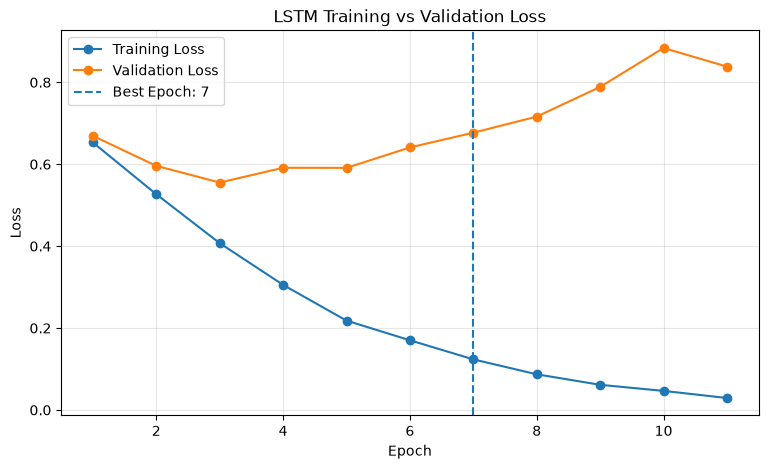

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Save the training history

In [60]:
history_path = CHECKPOINT_DIR / "training_history.csv"

history_df.to_csv(history_path, index=False)

print("Training history saved:", history_path)

Training history saved: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/artifacts/sentiment/lstm/training_history.csv


## Step 13 — Final LSTM test evaluation

In [61]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

### Generate test predictions

In [62]:
@torch.inference_mode()
def predict_probabilities(model, loader, device):

    model.eval()

    all_probabilities = []
    all_labels = []

    for inputs, lengths, labels in loader:

        inputs = inputs.to(device, non_blocking=True)

        logits = model(inputs, lengths)

        probabilities = torch.sigmoid(logits)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

    return (
        np.array(all_labels).astype(int),
        np.array(all_probabilities)
    )

In [63]:
test_labels, test_probabilities = predict_probabilities(
    model,
    test_loader,
    device
)

THRESHOLD = 0.5

test_predictions = (
    test_probabilities >= THRESHOLD
).astype(int)

print("Test samples:", len(test_labels))
print("Predictions:", test_predictions.shape)
print("Probabilities:", test_probabilities.shape)

Test samples: 600
Predictions: (600,)
Probabilities: (600,)


### Calculate evaluation metrics

In [64]:
test_metrics = {
    "accuracy": accuracy_score(
        test_labels, test_predictions
    ),
    "balanced_accuracy": balanced_accuracy_score(
        test_labels, test_predictions
    ),
    "precision_macro": precision_score(
        test_labels, test_predictions, average="macro"
    ),
    "recall_macro": recall_score(
        test_labels, test_predictions, average="macro"
    ),
    "f1_macro": f1_score(
        test_labels, test_predictions, average="macro"
    ),
    "roc_auc": roc_auc_score(
        test_labels, test_probabilities
    ),
    "average_precision": average_precision_score(
        test_labels, test_probabilities
    )
}

for metric, value in test_metrics.items():
    print(f"{metric:25s}: {value:.4f}")

accuracy                 : 0.7567
balanced_accuracy        : 0.7567
precision_macro          : 0.7567
recall_macro             : 0.7567
f1_macro                 : 0.7567
roc_auc                  : 0.8281
average_precision        : 0.8159


### Generate the confusion matrix

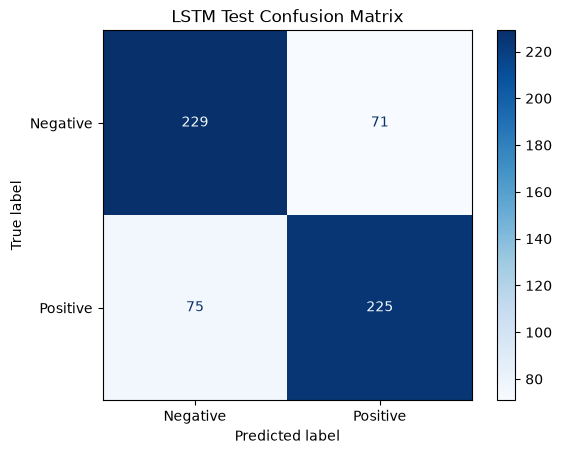

In [65]:
cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot(cmap="Blues", values_format="d")

plt.title("LSTM Test Confusion Matrix")
plt.show()

### Classification report

In [66]:
print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=["Negative", "Positive"],
        digits=4
    )
)

              precision    recall  f1-score   support

    Negative     0.7533    0.7633    0.7583       300
    Positive     0.7601    0.7500    0.7550       300

    accuracy                         0.7567       600
   macro avg     0.7567    0.7567    0.7567       600
weighted avg     0.7567    0.7567    0.7567       600



## Classical ML vs LSTM


| Metric | TF-IDF + MultinomialNB | LSTM |
| :--- | :--- | :--- |
| **Accuracy** | 84.83% | 75.67% |
| **Macro F1** | 0.8483 | 0.7567 |
| **ROC-AUC** | 0.9209 | 0.8281 |
| **Average precision** | 0.9230 | 0.8159 |

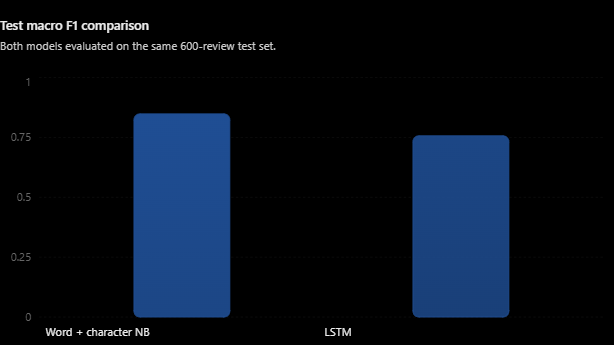

In [67]:
from IPython.display import Image, display
display(Image(filename='plots/Test macro F1 comparison.png'))

The classical model also produces fewer classification errors:
- MultinomialNB: 91 errors.
- LSTM: 146 errors.


Why might our LSTM be underperforming?
Based on our experiments, three hypotheses deserve investigation:

1. Limited training data

We have only 1,920 training sentences. That's relatively small for learning useful word embeddings from scratch.

2. Overfitting

At epoch 7, training accuracy reached 96.09%, while validation accuracy was only 77.71%.

3. Embeddings learned from scratch

Our LSTM must learn both word representations and sentiment classification from the same small dataset. TF-IDF already provides a useful representation without requiring this additional learning.

These are hypotheses, not yet proven explanations.

## Step 14 — LSTM Error Analysis.

Before changing the architecture, we should understand why our LSTM is making incorrect predictions. This is an important part of professional ML development: diagnose the model before attempting to improve it.

### Generate validation predictions

In [68]:
val_labels, val_probabilities = predict_probabilities(
    model,
    val_loader,
    device
)

val_predictions = (
    val_probabilities >= 0.5
).astype(int)

print("Validation samples:", len(val_labels))
print("Prediction shape:", val_predictions.shape)
print("Probability shape:", val_probabilities.shape)

Validation samples: 480
Prediction shape: (480,)
Probability shape: (480,)


In [69]:
assert np.array_equal(
    val_labels,
    validation_df["label"].to_numpy()
)

print("Validation prediction alignment verified.")

Validation prediction alignment verified.


### Create an error analysis DataFrame

In [70]:
validation_analysis = validation_df.copy()

validation_analysis["predicted_label"] = val_predictions

validation_analysis["predicted_probability"] = val_probabilities

validation_analysis["confidence"] = np.where(
    val_predictions == 1,
    val_probabilities,
    1 - val_probabilities
)

validation_analysis["error_type"] = np.select(
    [
        (validation_analysis["label"] == 0) &
        (validation_analysis["predicted_label"] == 1),

        (validation_analysis["label"] == 1) &
        (validation_analysis["predicted_label"] == 0)
    ],
    [
        "False Positive",
        "False Negative"
    ],
    default="Correct"
)

print(validation_analysis["error_type"].value_counts())

error_type
Correct           373
False Negative     56
False Positive     51
Name: count, dtype: int64


### Inspect incorrectly classified reviews

In [71]:
misclassified = validation_analysis[
    validation_analysis["error_type"] != "Correct"
].copy()

misclassified = misclassified.sort_values(
    "confidence",
    ascending=False
)

columns_to_display = [
    "text",
    "label",
    "predicted_label",
    "predicted_probability",
    "confidence",
    "error_type"
]

if "source" in misclassified.columns:
    columns_to_display.insert(1, "source")

display(
    misclassified[columns_to_display].head(15)
)

,text,source,label,predicted_label,predicted_probability,confidence,error_type
247,Full of unconvincing cardboard characters it i...,imdb,0,1,0.998560,0.998560,False Positive
403,Seafood was limited to boiled shrimp and crab ...,yelp,0,1,0.997317,0.997317,False Positive
141,The pairing of the two devices was so easy it ...,amazon,1,0,0.003026,0.996974,False Negative
233,I would have casted her in that role after rea...,imdb,1,0,0.003722,0.996278,False Negative
77,Unfortunately the ability to actually know you...,amazon,0,1,0.995894,0.995894,False Positive
111,Think it over when you plan to own this one!Th...,amazon,0,1,0.995589,0.995589,False Positive
179,These are the central themes of the film and t...,imdb,0,1,0.995560,0.995560,False Positive
181,NOBODY identifies with these characters becaus...,imdb,0,1,0.995523,0.995523,False Positive
286,I liked the way Dustin Hoffman's character was...,imdb,1,0,0.004754,0.995246,False Negative
56,I was able to do voice dialing in the car with...,amazon,1,0,0.004808,0.995192,False Negative


Why inspect high-confidence mistakes?

A model that predicts the wrong class with 98% confidence deserves more investigation than one that makes an uncertain prediction near 50%.

Possible causes include sarcasm, mixed sentiment, negation, ambiguous language, or domain-specific expressions. We'll determine which patterns actually occur in your examples rather than assume.

### Examine errors by review source

In [72]:
if "source" in validation_analysis.columns:

    source_error_summary = (
        validation_analysis
        .groupby("source")
        .agg(
            total_reviews=("label", "size"),
            accuracy=(
                "label",
                lambda actual: np.mean(
                    actual.to_numpy() ==
                    validation_analysis.loc[
                        actual.index, "predicted_label"
                    ].to_numpy()
                )
            ),
            errors=(
                "error_type",
                lambda values: (values != "Correct").sum()
            ),
            false_positives=(
                "error_type",
                lambda values: (values == "False Positive").sum()
            ),
            false_negatives=(
                "error_type",
                lambda values: (values == "False Negative").sum()
            )
        )
        .reset_index()
    )

    display(source_error_summary.round(4))
else:
    print("No source column found:", validation_analysis.columns.tolist())

,source,total_reviews,accuracy,errors,false_positives,false_negatives
0,amazon,160,0.8188,29,12,17
1,imdb,160,0.6938,49,26,23
2,yelp,160,0.8188,29,13,16


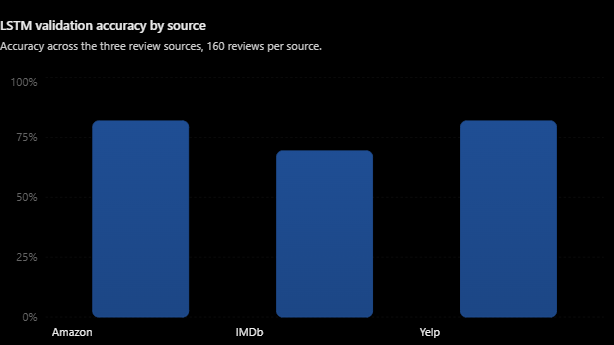

In [73]:
from IPython.display import Image, display
display(Image(filename='plots/LSTM validation accuracy by source.png'))

IMDb has approximately 12.5 percentage points lower accuracy than Amazon and Yelp.

This could indicate that the model has difficulty generalizing to different language patterns, vocabulary, or writing styles found in movie reviews. We need further evidence before identifying the cause.

### Inspect the complete misclassified reviews

In [74]:
for idx, row in misclassified.head(15).iterrows():

    true_label = "Positive" if row["label"] == 1 else "Negative"

    predicted_label = (
        "Positive" if row["predicted_label"] == 1
        else "Negative"
    )

    print("=" * 100)
    print(f"Original index: {idx}")
    print(f"Source: {row['source']}")
    print(f"Actual sentiment: {true_label}")
    print(f"Predicted sentiment: {predicted_label}")
    print(f"Positive probability: {row['predicted_probability']:.6f}")
    print(f"Confidence: {row['confidence']:.6f}")
    print(f"Error type: {row['error_type']}")
    print("\nComplete review:")
    print(row["text"])
    print()

Original index: 247
Source: imdb
Actual sentiment: Negative
Predicted sentiment: Positive
Positive probability: 0.998560
Confidence: 0.998560
Error type: False Positive

Complete review:
Full of unconvincing cardboard characters it is blandly written by Edward Chodorov, who also produced, and is surprisingly directed by Jean Negulesco from whom one would expect a great deal more.

Original index: 403
Source: yelp
Actual sentiment: Negative
Predicted sentiment: Positive
Positive probability: 0.997317
Confidence: 0.997317
Error type: False Positive

Complete review:
Seafood was limited to boiled shrimp and crab legs but the crab legs definitely did not taste fresh.

Original index: 141
Source: amazon
Actual sentiment: Positive
Predicted sentiment: Negative
Positive probability: 0.003026
Confidence: 0.996974
Error type: False Negative

Complete review:
The pairing of the two devices was so easy it barely took a couple minutes before I started making calls with the voice dialing feature.



### Create diagnostic features

In [75]:
def get_text_diagnostics(text):

    tokens = tokenize(text)

    token_ids = encode_text(text, vocab)

    total_tokens = len(tokens)

    unknown_tokens = sum(
        token_id == vocab[UNK_TOKEN]
        for token_id in token_ids
    )

    return pd.Series({
        "token_count": total_tokens,
        "unknown_count": unknown_tokens,
        "unknown_rate": (
            unknown_tokens / total_tokens
            if total_tokens > 0 else 0
        ),
        "was_truncated": total_tokens > MAX_LEN
    })

### Apply diagnostics to validation reviews

In [76]:
diagnostics = validation_analysis["text"].apply(
    get_text_diagnostics
)

validation_analysis = pd.concat(
    [validation_analysis, diagnostics],
    axis=1
)

display(
    validation_analysis.head()
)

,record_id,source,text,label,group_id,predicted_label,predicted_probability,confidence,error_type,token_count,unknown_count,unknown_rate,was_truncated
0,amazon_0003,amazon,Great for the jawbone.,1,bbe8ef479eb7662324cb,1,0.995488,0.995488,Correct,4,1,0.250000,False
1,amazon_0005,amazon,The mic is great.,1,79a22edacb9c51006573,1,0.963118,0.963118,Correct,4,0,0.000000,False
2,amazon_0007,amazon,If you have several dozen or several hundred c...,0,2e1a4688aec13cbb8968,0,0.037910,0.962090,Correct,21,4,0.190476,False
3,amazon_0009,amazon,"Needless to say, I wasted my money.",0,8d001610d1249df2960c,0,0.032679,0.967321,Correct,7,0,0.000000,False
4,amazon_0010,amazon,What a waste of money and time!.,0,cb0dc0850ddc8cfd4c32,0,0.013702,0.986298,Correct,7,0,0.000000,False


### Compare correctly and incorrectly classified reviews

In [77]:
error_diagnostics = (
    validation_analysis
    .groupby("error_type")
    .agg(
        review_count=("text", "size"),
        avg_token_count=("token_count", "mean"),
        avg_unknown_count=("unknown_count", "mean"),
        avg_unknown_rate=("unknown_rate", "mean"),
        truncated_reviews=("was_truncated", "sum")
    )
    .reset_index()
)

display(error_diagnostics.round(4))

,error_type,review_count,avg_token_count,avg_unknown_count,avg_unknown_rate,truncated_reviews
0,Correct,373,11.8633,1.8686,0.1435,3
1,False Negative,56,13.7857,2.7679,0.2124,0
2,False Positive,51,13.3529,2.8235,0.1928,1


### Investigate unknown words in misclassified reviews

In [78]:
unknown_word_counts = Counter()

for text in misclassified["text"]:

    tokens = tokenize(text)

    for token in tokens:

        if token not in vocab:
            unknown_word_counts[token] += 1

print("Most frequent unknown words in misclassified reviews:")

display(
    pd.DataFrame(
        unknown_word_counts.most_common(20),
        columns=["word", "count"]
    )
)

Most frequent unknown words in misclassified reviews:


,word,count
0,feature,3
1,unconvincing,2
2,cardboard,2
3,produced,2
4,crab,2
5,legs,2
6,dialing,2
7,stereotypes,2
8,stunning,2
9,fx,2


## Step 15 Experiment 2: Increase Dropout

### Initialize the regularized model

In [79]:
DROPOUT_EXP2 = 0.5

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Create a separate model
regularized_model = SentimentLSTM(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    dropout=DROPOUT_EXP2
).to(device)

criterion_exp2 = nn.BCEWithLogitsLoss()

optimizer_exp2 = torch.optim.Adam(
    regularized_model.parameters(),
    lr=0.001
)

checkpoint_exp2 = (
    CHECKPOINT_DIR / "best_lstm_dropout_05.pt"
)

print(regularized_model)
print("\nDropout:", DROPOUT_EXP2)
print("Checkpoint:", checkpoint_exp2)

SentimentLSTM(
  (embedding): Embedding(1619, 100, padding_idx=0)
  (lstm): LSTM(100, 64, batch_first=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

Dropout: 0.5
Checkpoint: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/artifacts/sentiment/lstm/best_lstm_dropout_05.pt


### Train the new experiment

In [80]:
history_exp2 = []

best_f1_exp2 = -float("inf")
best_epoch_exp2 = 0
patience_counter_exp2 = 0

for epoch in range(1, NUM_EPOCHS + 1):

    # Training
    train_one_epoch(
        regularized_model,
        train_loader,
        criterion_exp2,
        optimizer_exp2,
        device
    )

    # Training evaluation
    tr_loss, tr_acc, tr_f1 = evaluate(
        regularized_model,
        train_loader,
        criterion_exp2,
        device
    )

    # Validation evaluation
    v_loss, v_acc, v_f1 = evaluate(
        regularized_model,
        val_loader,
        criterion_exp2,
        device
    )

    history_exp2.append({
        "epoch": epoch,
        "train_loss": tr_loss,
        "train_accuracy": tr_acc,
        "train_macro_f1": tr_f1,
        "val_loss": v_loss,
        "val_accuracy": v_acc,
        "val_macro_f1": v_f1
    })

    if v_f1 > best_f1_exp2 + MIN_DELTA:

        best_f1_exp2 = v_f1
        best_epoch_exp2 = epoch
        patience_counter_exp2 = 0

        torch.save(
            regularized_model.state_dict(),
            checkpoint_exp2
        )

        status = "Best model saved"

    else:
        patience_counter_exp2 += 1
        status = f"No improvement: {patience_counter_exp2}/{PATIENCE}"

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {tr_loss:.4f} | "
        f"Train Acc: {tr_acc:.4f} | "
        f"Val Loss: {v_loss:.4f} | "
        f"Val Acc: {v_acc:.4f} | "
        f"Val F1: {v_f1:.4f} | "
        f"{status}"
    )

    if patience_counter_exp2 >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Restore best checkpoint
regularized_model.load_state_dict(
    torch.load(
        checkpoint_exp2,
        map_location=device,
        weights_only=True
    )
)

print("\nBest epoch:", best_epoch_exp2)
print("Best validation macro F1:", round(best_f1_exp2, 4))

Epoch 01 | Train Loss: 0.6604 | Train Acc: 0.6828 | Val Loss: 0.6734 | Val Acc: 0.6208 | Val F1: 0.6203 | Best model saved
Epoch 02 | Train Loss: 0.5660 | Train Acc: 0.7448 | Val Loss: 0.6156 | Val Acc: 0.6792 | Val F1: 0.6769 | Best model saved
Epoch 03 | Train Loss: 0.4378 | Train Acc: 0.8396 | Val Loss: 0.5554 | Val Acc: 0.7375 | Val F1: 0.7370 | Best model saved
Epoch 04 | Train Loss: 0.3562 | Train Acc: 0.8677 | Val Loss: 0.5934 | Val Acc: 0.7500 | Val F1: 0.7468 | Best model saved
Epoch 05 | Train Loss: 0.2474 | Train Acc: 0.9276 | Val Loss: 0.5609 | Val Acc: 0.7937 | Val F1: 0.7933 | Best model saved
Epoch 06 | Train Loss: 0.1969 | Train Acc: 0.9391 | Val Loss: 0.5944 | Val Acc: 0.7583 | Val F1: 0.7583 | No improvement: 1/4
Epoch 07 | Train Loss: 0.1368 | Train Acc: 0.9594 | Val Loss: 0.6514 | Val Acc: 0.7896 | Val F1: 0.7895 | No improvement: 2/4
Epoch 08 | Train Loss: 0.1036 | Train Acc: 0.9745 | Val Loss: 0.6628 | Val Acc: 0.7771 | Val F1: 0.7771 | No improvement: 3/4
Epoch 0

### Compare the experiments

In [81]:
comparison = pd.DataFrame([
    {
        "experiment": "Baseline LSTM (Dropout 0.3)",
        "best_epoch": best_epoch,
        "validation_macro_f1": 0.7771
    },
    {
        "experiment": "Regularized LSTM (Dropout 0.5)",
        "best_epoch": best_epoch_exp2,
        "validation_macro_f1": best_f1_exp2
    }
])

display(comparison)

,experiment,best_epoch,validation_macro_f1
0,Baseline LSTM (Dropout 0.3),7,0.777100
1,Regularized LSTM (Dropout 0.5),5,0.793275



| Metric | Baseline: Dropout 0.3 | Experiment 2: Dropout 0.5 |
| :--- | :--- | :--- |
| **Best epoch** | 7 | 5 |
| **Validation accuracy** | 77.71% | 79.37% |
| **Validation macro F1** | 0.7771 | 0.7933 |
| **Training accuracy at best epoch** | 96.09% | 92.76% |
| **Train-validation accuracy gap** | 18.38 pp | 13.39 pp |



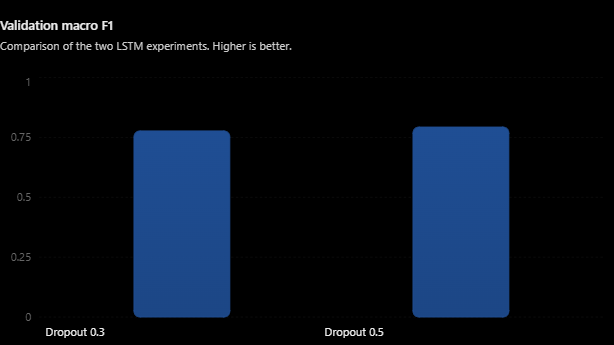

In [82]:
from IPython.display import Image, display
display(Image(filename='plots/Validation macro F1.png'))

## Step 16 — Experiment 3: Introduce weight decay

What is weight decay?

Weight decay penalizes large model weights during optimization. It encourages the model to avoid relying excessively on very large parameter values.


| Parameter | Experiment 2 | Experiment 3 |
| :--- | :--- | :--- |
| **Embedding dimension** | 100 | 100 |
| **Hidden size** | 64 | 64 |
| **Dropout** | 0.5 | 0.5 |
| **Learning rate** | 0.001 | 0.001 |
| **Weight decay** | 0 | 0.0001 |



### Initialize the experiment

In [83]:
pd.DataFrame(history_exp2).to_csv(
    CHECKPOINT_DIR / "history_dropout_05.csv",
    index=False
)

In [84]:
WEIGHT_DECAY_EXP3 = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_exp3 = SentimentLSTM(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    dropout=0.5
).to(device)

criterion_exp3 = nn.BCEWithLogitsLoss()

optimizer_exp3 = torch.optim.Adam(
    model_exp3.parameters(),
    lr=0.001,
    weight_decay=WEIGHT_DECAY_EXP3
)

checkpoint_exp3 = (
    CHECKPOINT_DIR / "best_lstm_dropout_05_wd_1e-4.pt"
)

print("Weight decay:", WEIGHT_DECAY_EXP3)
print("Optimizer:", optimizer_exp3)
print("Model parameters:", sum(
    p.numel() for p in model_exp3.parameters()
))

Weight decay: 0.0001
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Model parameters: 204461


### Train Experiment 3

In [85]:
history_exp3 = []

best_f1_exp3 = -float("inf")
best_epoch_exp3 = 0
patience_counter_exp3 = 0

for epoch in range(1, NUM_EPOCHS + 1):

    train_one_epoch(
        model_exp3,
        train_loader,
        criterion_exp3,
        optimizer_exp3,
        device
    )

    tr_loss, tr_acc, tr_f1 = evaluate(
        model_exp3,
        train_loader,
        criterion_exp3,
        device
    )

    v_loss, v_acc, v_f1 = evaluate(
        model_exp3,
        val_loader,
        criterion_exp3,
        device
    )

    history_exp3.append({
        "epoch": epoch,
        "train_loss": tr_loss,
        "train_accuracy": tr_acc,
        "train_macro_f1": tr_f1,
        "val_loss": v_loss,
        "val_accuracy": v_acc,
        "val_macro_f1": v_f1
    })

    if v_f1 > best_f1_exp3 + MIN_DELTA:

        best_f1_exp3 = v_f1
        best_epoch_exp3 = epoch
        patience_counter_exp3 = 0

        torch.save(
            model_exp3.state_dict(),
            checkpoint_exp3
        )

        status = "Best model saved"

    else:
        patience_counter_exp3 += 1
        status = f"No improvement: {patience_counter_exp3}/{PATIENCE}"

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {tr_loss:.4f} | "
        f"Train Acc: {tr_acc:.4f} | "
        f"Val Loss: {v_loss:.4f} | "
        f"Val Acc: {v_acc:.4f} | "
        f"Val F1: {v_f1:.4f} | "
        f"{status}"
    )

    if patience_counter_exp3 >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

model_exp3.load_state_dict(
    torch.load(
        checkpoint_exp3,
        map_location=device,
        weights_only=True
    )
)

print("\nBest epoch:", best_epoch_exp3)
print("Best validation macro F1:", round(best_f1_exp3, 4))

Epoch 01 | Train Loss: 0.6631 | Train Acc: 0.6740 | Val Loss: 0.6746 | Val Acc: 0.6188 | Val F1: 0.6182 | Best model saved
Epoch 02 | Train Loss: 0.5839 | Train Acc: 0.7250 | Val Loss: 0.6239 | Val Acc: 0.6646 | Val F1: 0.6616 | Best model saved
Epoch 03 | Train Loss: 0.4697 | Train Acc: 0.8146 | Val Loss: 0.5628 | Val Acc: 0.7396 | Val F1: 0.7396 | Best model saved
Epoch 04 | Train Loss: 0.3838 | Train Acc: 0.8500 | Val Loss: 0.5791 | Val Acc: 0.7333 | Val F1: 0.7315 | No improvement: 1/4
Epoch 05 | Train Loss: 0.3107 | Train Acc: 0.8854 | Val Loss: 0.5695 | Val Acc: 0.7583 | Val F1: 0.7568 | Best model saved
Epoch 06 | Train Loss: 0.2495 | Train Acc: 0.9193 | Val Loss: 0.5568 | Val Acc: 0.7583 | Val F1: 0.7582 | Best model saved
Epoch 07 | Train Loss: 0.1963 | Train Acc: 0.9328 | Val Loss: 0.5975 | Val Acc: 0.7583 | Val F1: 0.7578 | No improvement: 1/4
Epoch 08 | Train Loss: 0.1488 | Train Acc: 0.9542 | Val Loss: 0.6392 | Val Acc: 0.7708 | Val F1: 0.7707 | Best model saved
Epoch 09 |

### Compare all three experiments

In [86]:
comparison_exp3 = pd.DataFrame([
    {
        "experiment": "Baseline LSTM - Dropout 0.3",
        "best_epoch": best_epoch,
        "validation_macro_f1": 0.7771
    },
    {
        "experiment": "Dropout 0.5",
        "best_epoch": best_epoch_exp2,
        "validation_macro_f1": best_f1_exp2
    },
    {
        "experiment": "Dropout 0.5 + Weight Decay",
        "best_epoch": best_epoch_exp3,
        "validation_macro_f1": best_f1_exp3
    }
])

display(comparison_exp3)

,experiment,best_epoch,validation_macro_f1
0,Baseline LSTM - Dropout 0.3,7,0.777100
1,Dropout 0.5,5,0.793275
2,Dropout 0.5 + Weight Decay,8,0.770734


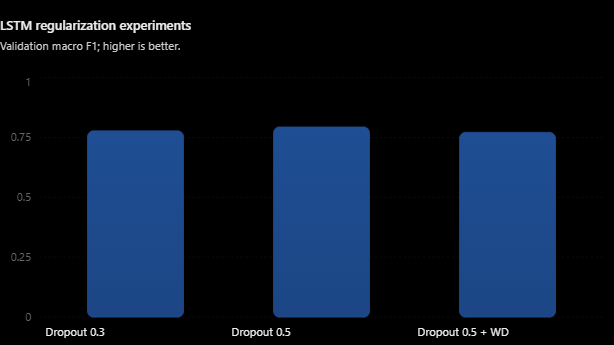

In [87]:
from IPython.display import Image, display
display(Image(filename='plots/LSTM regularization experiments.png'))

## Step 16 — Experiment 4: Reduce embedding dimension

Now let's investigate whether reducing model capacity helps generalization.

Our current embedding dimension is 100. Every vocabulary word has a trainable 100-dimensional vector.


| Parameter | Current champion | Experiment 4 |
| :--- | :--- | :--- |
| **Vocabulary size** | 1,619 | 1,619 |
| **Embedding dimension** | 100 | 50 |
| **LSTM hidden size** | 64 | 64 |
| **Dropout** | 0.5 | 0.5 |
| **Learning rate** | 0.001 | 0.001 |
| **Weight decay** | 0 | 0.0 |


In [88]:
EMBEDDING_DIM_EXP4 = 50
HIDDEN_DIM_EXP4 = 64
DROPOUT_EXP4 = 0.5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_exp4 = SentimentLSTM(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM_EXP4,
    hidden_dim=HIDDEN_DIM_EXP4,
    dropout=DROPOUT_EXP4
).to(device)

criterion_exp4 = nn.BCEWithLogitsLoss()

optimizer_exp4 = torch.optim.Adam(
    model_exp4.parameters(),
    lr=0.001,
    weight_decay=0
)

checkpoint_exp4 = (
    CHECKPOINT_DIR / "best_lstm_embedding_50.pt"
)

total_parameters_exp4 = sum(
    p.numel() for p in model_exp4.parameters()
)

print(model_exp4)
print("\nEmbedding dimension:", EMBEDDING_DIM_EXP4)
print("Total parameters:", total_parameters_exp4)
print("Device:", next(model_exp4.parameters()).device)

SentimentLSTM(
  (embedding): Embedding(1619, 50, padding_idx=0)
  (lstm): LSTM(50, 64, batch_first=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

Embedding dimension: 50
Total parameters: 110711
Device: cuda:0


### Train Experiment 4

In [89]:
history_exp4 = []

best_f1_exp4 = -float("inf")
best_epoch_exp4 = 0
patience_counter_exp4 = 0

for epoch in range(1, NUM_EPOCHS + 1):

    # Train
    train_one_epoch(
        model_exp4,
        train_loader,
        criterion_exp4,
        optimizer_exp4,
        device
    )

    # Evaluate training data
    tr_loss, tr_acc, tr_f1 = evaluate(
        model_exp4,
        train_loader,
        criterion_exp4,
        device
    )

    # Evaluate validation data
    v_loss, v_acc, v_f1 = evaluate(
        model_exp4,
        val_loader,
        criterion_exp4,
        device
    )

    history_exp4.append({
        "epoch": epoch,
        "train_loss": tr_loss,
        "train_accuracy": tr_acc,
        "train_macro_f1": tr_f1,
        "val_loss": v_loss,
        "val_accuracy": v_acc,
        "val_macro_f1": v_f1
    })

    if v_f1 > best_f1_exp4 + MIN_DELTA:

        best_f1_exp4 = v_f1
        best_epoch_exp4 = epoch
        patience_counter_exp4 = 0

        torch.save(
            model_exp4.state_dict(),
            checkpoint_exp4
        )

        status = "Best model saved"

    else:
        patience_counter_exp4 += 1
        status = f"No improvement: {patience_counter_exp4}/{PATIENCE}"

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {tr_loss:.4f} | "
        f"Train Acc: {tr_acc:.4f} | "
        f"Val Loss: {v_loss:.4f} | "
        f"Val Acc: {v_acc:.4f} | "
        f"Val F1: {v_f1:.4f} | "
        f"{status}"
    )

    if patience_counter_exp4 >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Restore the best checkpoint
model_exp4.load_state_dict(
    torch.load(
        checkpoint_exp4,
        map_location=device,
        weights_only=True
    )
)

print("\nBest epoch:", best_epoch_exp4)
print("Best validation macro F1:", round(best_f1_exp4, 4))

Epoch 01 | Train Loss: 0.6766 | Train Acc: 0.6375 | Val Loss: 0.6838 | Val Acc: 0.5500 | Val F1: 0.5485 | Best model saved
Epoch 02 | Train Loss: 0.6249 | Train Acc: 0.7130 | Val Loss: 0.6584 | Val Acc: 0.5771 | Val F1: 0.5737 | Best model saved
Epoch 03 | Train Loss: 0.5292 | Train Acc: 0.7766 | Val Loss: 0.6086 | Val Acc: 0.6604 | Val F1: 0.6604 | Best model saved
Epoch 04 | Train Loss: 0.4324 | Train Acc: 0.8224 | Val Loss: 0.5767 | Val Acc: 0.7146 | Val F1: 0.7146 | Best model saved
Epoch 05 | Train Loss: 0.3687 | Train Acc: 0.8557 | Val Loss: 0.5888 | Val Acc: 0.7188 | Val F1: 0.7177 | Best model saved
Epoch 06 | Train Loss: 0.3178 | Train Acc: 0.8891 | Val Loss: 0.5566 | Val Acc: 0.7167 | Val F1: 0.7145 | No improvement: 1/4
Epoch 07 | Train Loss: 0.2397 | Train Acc: 0.9125 | Val Loss: 0.5512 | Val Acc: 0.7312 | Val F1: 0.7312 | Best model saved
Epoch 08 | Train Loss: 0.1920 | Train Acc: 0.9318 | Val Loss: 0.6397 | Val Acc: 0.7396 | Val F1: 0.7395 | Best model saved
Epoch 09 | Tr

### Compare all four experiments

In [90]:
comparison_exp4 = pd.DataFrame([
    {
        "experiment": "Baseline LSTM - Dropout 0.3",
        "best_epoch": best_epoch,
        "validation_macro_f1": 0.777100
    },
    {
        "experiment": "Dropout 0.5",
        "best_epoch": best_epoch_exp2,
        "validation_macro_f1": best_f1_exp2
    },
    {
        "experiment": "Dropout 0.5 + Weight Decay",
        "best_epoch": best_epoch_exp3,
        "validation_macro_f1": best_f1_exp3
    },
    {
        "experiment": "Embedding 50 + Dropout 0.5",
        "best_epoch": best_epoch_exp4,
        "validation_macro_f1": best_f1_exp4
    }
])

display(
    comparison_exp4.sort_values(
        "validation_macro_f1",
        ascending=False
    )
)

,experiment,best_epoch,validation_macro_f1
1,Dropout 0.5,5,0.793275
0,Baseline LSTM - Dropout 0.3,7,0.777100
2,Dropout 0.5 + Weight Decay,8,0.770734
3,Embedding 50 + Dropout 0.5,17,0.766602


In [91]:
pd.DataFrame(history_exp4).to_csv(
    CHECKPOINT_DIR / "history_embedding_50.csv",
    index=False
)

## Step 17 — Optuna Hyperparameter Optimization

In [27]:
import optuna

from sklearn.model_selection import StratifiedGroupKFold

/home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [39]:
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

y_train_array = train_df["label"].to_numpy()
groups = train_df["group_id"].to_numpy()

cv_splits = list(
    cv.split(
        train_df["text"],
        y_train_array,
        groups=groups
    )
)

print("Number of folds:", len(cv_splits))

Number of folds: 3


### Inspect each fold:

In [40]:
for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):

    fold_train = train_df.iloc[train_idx]
    fold_val = train_df.iloc[val_idx]

    train_groups = set(fold_train["group_id"])
    val_groups = set(fold_val["group_id"])

    assert train_groups.isdisjoint(val_groups)

    print(f"\nFOLD {fold}")
    print("-" * 40)

    print("Training samples:", len(fold_train))
    print("Validation samples:", len(fold_val))

    print("\nTraining label distribution:")
    print(fold_train["label"].value_counts().sort_index())

    print("\nValidation label distribution:")
    print(fold_val["label"].value_counts().sort_index())

    print("\nTraining source distribution:")
    print(fold_train["source"].value_counts())

    print("\nValidation source distribution:")
    print(fold_val["source"].value_counts())

    print("Duplicate-group leakage: None")


FOLD 1
----------------------------------------
Training samples: 1280
Validation samples: 640

Training label distribution:
label
0    640
1    640
Name: count, dtype: int64

Validation label distribution:
label
0    320
1    320
Name: count, dtype: int64

Training source distribution:
source
amazon    444
yelp      438
imdb      398
Name: count, dtype: int64

Validation source distribution:
source
imdb      242
yelp      202
amazon    196
Name: count, dtype: int64
Duplicate-group leakage: None

FOLD 2
----------------------------------------
Training samples: 1280
Validation samples: 640

Training label distribution:
label
0    640
1    640
Name: count, dtype: int64

Validation label distribution:
label
0    320
1    320
Name: count, dtype: int64

Training source distribution:
source
amazon    434
imdb      429
yelp      417
Name: count, dtype: int64

Validation source distribution:
source
yelp      223
imdb      211
amazon    206
Name: count, dtype: int64
Duplicate-group leakage: N

## Step 18 — Improve the cross-validation splits

In [41]:
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

# Combine source and sentiment into six stratification categories
stratification_labels = (
    train_df["source"].astype(str)
    + "__"
    + train_df["label"].astype(str)
)

groups = train_df["group_id"].to_numpy()

cv_splits = list(
    cv.split(
        train_df["text"],
        stratification_labels,
        groups=groups
    )
)

print("Number of folds:", len(cv_splits))
print("Stratification categories:")
print(stratification_labels.value_counts().sort_index())

Number of folds: 3
Stratification categories:
amazon__0    320
amazon__1    320
imdb__0      320
imdb__1      320
yelp__0      320
yelp__1      320
Name: count, dtype: int64


### Inspect the new folds

In [42]:
for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):

    fold_train = train_df.iloc[train_idx]
    fold_val = train_df.iloc[val_idx]

    train_groups = set(fold_train["group_id"])
    val_groups = set(fold_val["group_id"])

    assert train_groups.isdisjoint(val_groups)

    print(f"\nFOLD {fold}")
    print("-" * 45)

    print("Training samples:", len(fold_train))
    print("Validation samples:", len(fold_val))

    print("\nTraining source-label distribution:")
    display(pd.crosstab(fold_train["source"], fold_train["label"]))

    print("\nValidation source-label distribution:")
    display(pd.crosstab(fold_val["source"], fold_val["label"]))

    print("Group leakage:", len(train_groups.intersection(val_groups)))


FOLD 1
---------------------------------------------
Training samples: 1280
Validation samples: 640

Training source-label distribution:


label,0,1
source,,
amazon,214,213
imdb,213,213
yelp,214,213



Validation source-label distribution:


label,0,1
source,,
amazon,106,107
imdb,107,107
yelp,106,107


Group leakage: 0

FOLD 2
---------------------------------------------
Training samples: 1280
Validation samples: 640

Training source-label distribution:


label,0,1
source,,
amazon,213,213
imdb,213,214
yelp,213,214


... (3 outputs left out)

label,0,1
source,,
amazon,213,214
imdb,214,213
yelp,213,213



Validation source-label distribution:


label,0,1
source,,
amazon,107,106
imdb,106,107
yelp,107,107


Group leakage: 0


## Step 19 — Build fold-specific preprocessing

### Create a fold-specific vocabulary function

In [43]:
def build_fold_vocab(texts, min_freq=2):

    token_counts = Counter()

    # Count words from fold training data only
    for text in texts:
        token_counts.update(tokenize(text))

    # Reserve special tokens
    fold_vocab = {
        PAD_TOKEN: 0,
        UNK_TOKEN: 1
    }

    sorted_tokens = sorted(
        token_counts.items(),
        key=lambda item: (-item[1], item[0])
    )

    for token, count in sorted_tokens:

        if count >= min_freq:
            fold_vocab[token] = len(fold_vocab)

    return fold_vocab, token_counts

### Create a function to encode text

In [44]:
def encode_texts(texts, fold_vocab):

    encoded_sequences = []

    for text in texts:

        tokens = tokenize(text)

        token_ids = [
            fold_vocab.get(token, fold_vocab[UNK_TOKEN])
            for token in tokens
        ]

        encoded_sequences.append(token_ids)

    return encoded_sequences

### Create a function to prepare fold datasets

In [45]:
def prepare_fold_datasets(
    fold_train_df,
    fold_val_df,
    min_freq=2,
    max_len_percentile=99
):

    # 1. Build vocabulary from training text only
    fold_vocab, token_counts = build_fold_vocab(
        fold_train_df["text"],
        min_freq=min_freq
    )

    # 2. Encode both datasets using training vocabulary
    train_sequences = encode_texts(
        fold_train_df["text"],
        fold_vocab
    )

    val_sequences = encode_texts(
        fold_val_df["text"],
        fold_vocab
    )

    # 3. Derive maximum length using fold training data only
    train_raw_lengths = np.array([
        len(sequence) for sequence in train_sequences
    ])

    fold_max_len = max(
        1,
        int(np.ceil(
            np.percentile(
                train_raw_lengths,
                max_len_percentile
            )
        ))
    )

    # 4. Pad sequences
    fold_pad_id = fold_vocab[PAD_TOKEN]

    X_train_fold = pad_sequences(
        train_sequences,
        fold_max_len,
        fold_pad_id
    )

    X_val_fold = pad_sequences(
        val_sequences,
        fold_max_len,
        fold_pad_id
    )

    # 5. Calculate actual sequence lengths
    train_lengths = torch.tensor(
        [min(len(seq), fold_max_len) for seq in train_sequences],
        dtype=torch.long
    )

    val_lengths = torch.tensor(
        [min(len(seq), fold_max_len) for seq in val_sequences],
        dtype=torch.long
    )

    # 6. Prepare labels
    y_train_fold = torch.tensor(
        fold_train_df["label"].to_numpy(),
        dtype=torch.float32
    )

    y_val_fold = torch.tensor(
        fold_val_df["label"].to_numpy(),
        dtype=torch.float32
    )

    # 7. Create PyTorch datasets
    fold_train_dataset = SentimentDataset(
        X_train_fold,
        train_lengths,
        y_train_fold
    )

    fold_val_dataset = SentimentDataset(
        X_val_fold,
        val_lengths,
        y_val_fold
    )

    return {
        "vocab": fold_vocab,
        "token_counts": token_counts,
        "max_len": fold_max_len,
        "train_dataset": fold_train_dataset,
        "val_dataset": fold_val_dataset
    }

### Test our preprocessing on Fold 1

In [46]:
fold_train_idx, fold_val_idx = cv_splits[0]

fold_train_df = train_df.iloc[fold_train_idx].reset_index(drop=True)
fold_val_df = train_df.iloc[fold_val_idx].reset_index(drop=True)

fold_data = prepare_fold_datasets(
    fold_train_df,
    fold_val_df,
    min_freq=2
)

print("Fold-specific vocabulary size:", len(fold_data["vocab"]))
print("Fold-specific maximum length:", fold_data["max_len"])

print("\nTraining dataset:", len(fold_data["train_dataset"]))
print("Validation dataset:", len(fold_data["val_dataset"]))

sample_input, sample_length, sample_label = (
    fold_data["train_dataset"][0]
)

print("\nSample input shape:", sample_input.shape)
print("Actual sequence length:", sample_length.item())
print("Sample label:", sample_label.item())

Fold-specific vocabulary size: 1198
Fold-specific maximum length: 36

Training dataset: 1280
Validation dataset: 640

Sample input shape: torch.Size([36])
Actual sequence length: 21
Sample label: 0.0


### Verify unknown-token handling

In [47]:
fold_val_sequences = encode_texts(
    fold_val_df["text"],
    fold_data["vocab"]
)

total_val_tokens = sum(
    len(tokenize(text))
    for text in fold_val_df["text"]
)

unknown_val_tokens = sum(
    token_id == fold_data["vocab"][UNK_TOKEN]
    for sequence in fold_val_sequences
    for token_id in sequence
)

print("Validation tokens:", total_val_tokens)
print("Unknown validation tokens:", unknown_val_tokens)

print(
    "Unknown token rate:",
    round(unknown_val_tokens / total_val_tokens, 4)
)

Validation tokens: 7616
Unknown validation tokens: 1401
Unknown token rate: 0.184


## Step 20 — Prepare all folds for hyperparameter tuning

### Define vocabulary thresholds

In [49]:
MIN_FREQ_OPTIONS = [1, 2, 3]
UNK_TOKEN_ID = 1

### Prepare all three folds

In [50]:
fold_cache = {}
fold_preprocessing_summary = []

for min_freq in MIN_FREQ_OPTIONS:

    fold_cache[min_freq] = []

    print(f"\nPreparing folds with MIN_FREQ = {min_freq}")
    print("-" * 55)

    for fold_number, (train_idx, val_idx) in enumerate(
        cv_splits, start=1
    ):

        fold_train_df = (
            train_df.iloc[train_idx].reset_index(drop=True)
        )

        fold_val_df = (
            train_df.iloc[val_idx].reset_index(drop=True)
        )

        # Prepare fold-specific vocabulary and datasets
        fold_data = prepare_fold_datasets(
            fold_train_df,
            fold_val_df,
            min_freq=min_freq
        )

        # Calculate validation unknown-token rate
        val_dataset = fold_data["val_dataset"]

        unknown_count = (
            val_dataset.input_ids == UNK_TOKEN_ID
        ).sum().item()

        total_val_tokens = val_dataset.lengths.sum().item()

        unknown_rate = unknown_count / total_val_tokens

        fold_cache[min_freq].append({
            "fold": fold_number,
            "train_dataset": fold_data["train_dataset"],
            "val_dataset": fold_data["val_dataset"],
            "vocab_size": len(fold_data["vocab"]),
            "max_len": fold_data["max_len"],
            "unknown_rate": unknown_rate
        })

        fold_preprocessing_summary.append({
            "min_freq": min_freq,
            "fold": fold_number,
            "vocab_size": len(fold_data["vocab"]),
            "max_len": fold_data["max_len"],
            "unknown_rate": unknown_rate
        })

        print(
            f"Fold {fold_number} | "
            f"Vocabulary: {len(fold_data['vocab'])} | "
            f"Max length: {fold_data['max_len']} | "
            f"Unknown rate: {unknown_rate:.4f}"
        )


Preparing folds with MIN_FREQ = 1
-------------------------------------------------------
Fold 1 | Vocabulary: 3196 | Max length: 36 | Unknown rate: 0.1228
Fold 2 | Vocabulary: 3166 | Max length: 42 | Unknown rate: 0.1256
Fold 3 | Vocabulary: 3097 | Max length: 36 | Unknown rate: 0.1327

Preparing folds with MIN_FREQ = 2
-------------------------------------------------------
Fold 1 | Vocabulary: 1198 | Max length: 36 | Unknown rate: 0.1821
Fold 2 | Vocabulary: 1226 | Max length: 42 | Unknown rate: 0.1860
Fold 3 | Vocabulary: 1181 | Max length: 36 | Unknown rate: 0.1934

Preparing folds with MIN_FREQ = 3
-------------------------------------------------------
Fold 1 | Vocabulary: 769 | Max length: 36 | Unknown rate: 0.2195
Fold 2 | Vocabulary: 782 | Max length: 42 | Unknown rate: 0.2285
Fold 3 | Vocabulary: 763 | Max length: 36 | Unknown rate: 0.2314


### Review preprocessing results

In [52]:
preprocessing_summary_df = pd.DataFrame(
    fold_preprocessing_summary
)

display(
    preprocessing_summary_df.round(4)
)

,min_freq,fold,vocab_size,max_len,unknown_rate
0,1,1,3196,36,0.1228
1,1,2,3166,42,0.1256
2,1,3,3097,36,0.1327
3,2,1,1198,36,0.1821
4,2,2,1226,42,0.1860
5,2,3,1181,36,0.1934
6,3,1,769,36,0.2195
7,3,2,782,42,0.2285
8,3,3,763,36,0.2314


In [53]:
display(
    preprocessing_summary_df
    .groupby("min_freq")
    .agg(
        average_vocab_size=("vocab_size", "mean"),
        average_unknown_rate=("unknown_rate", "mean"),
        maximum_unknown_rate=("unknown_rate", "max")
    )
    .round(4)
)

,average_vocab_size,average_unknown_rate,maximum_unknown_rate
min_freq,,,
1,3153.0000,0.1270,0.1327
2,1201.6667,0.1872,0.1934
3,771.3333,0.2265,0.2314


### Verify that the cache is complete

In [54]:
for min_freq in MIN_FREQ_OPTIONS:

    assert len(fold_cache[min_freq]) == 3

    for fold_data in fold_cache[min_freq]:

        assert len(fold_data["train_dataset"]) == 1280
        assert len(fold_data["val_dataset"]) == 640

print("All fold-specific preprocessing datasets verified.")

All fold-specific preprocessing datasets verified.


## Step 21 — Prepare reusable training components

### Create a seed function

In [55]:
def set_trial_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

### Create a fold-specific DataLoader function

In [56]:
def create_fold_loaders(
    fold_data,
    batch_size,
    fold_number,
    seed=SEED
):

    # Independent generator for reproducible shuffling
    generator = torch.Generator()

    generator.manual_seed(seed + fold_number)

    train_loader = DataLoader(
        fold_data["train_dataset"],
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        generator=generator
    )

    val_loader = DataLoader(
        fold_data["val_dataset"],
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, val_loader

### Create a dynamic model factory

In [57]:
def create_trial_model(
    vocab_size,
    embedding_dim,
    hidden_dim,
    dropout
):

    model = SentimentLSTM(
        vocab_size=vocab_size,
        embedding_dim=embedding_dim,
        hidden_dim=hidden_dim,
        dropout=dropout
    )

    return model.to(device)

In [58]:
model_example = create_trial_model(
    vocab_size=3196,
    embedding_dim=100,
    hidden_dim=64,
    dropout=0.5
)

print(model_example)

print(
    "Parameters:",
    sum(p.numel() for p in model_example.parameters())
)

SentimentLSTM(
  (embedding): Embedding(3196, 100, padding_idx=0)
  (lstm): LSTM(100, 64, batch_first=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
Parameters: 362161


### Run an integration check

In [59]:
# Choose one configuration for testing
test_min_freq = 1
test_fold_number = 1
test_embedding_dim = 100
test_hidden_dim = 64
test_dropout = 0.5
test_batch_size = 32

# Retrieve fold 1
test_fold_data = fold_cache[test_min_freq][0]

# Create DataLoaders
test_train_loader, test_val_loader = create_fold_loaders(
    test_fold_data,
    batch_size=test_batch_size,
    fold_number=test_fold_number
)

# Create model
test_model = create_trial_model(
    vocab_size=test_fold_data["vocab_size"],
    embedding_dim=test_embedding_dim,
    hidden_dim=test_hidden_dim,
    dropout=test_dropout
)

# Inspect one batch
test_inputs, test_lengths, test_labels = next(
    iter(test_train_loader)
)

print("Training batch:", test_inputs.shape)
print("Sequence lengths:", test_lengths.shape)
print("Labels:", test_labels.shape)

print("\nFold vocabulary:", test_fold_data["vocab_size"])
print("Model device:", next(test_model.parameters()).device)
print(
    "Model parameters:",
    sum(p.numel() for p in test_model.parameters())
)

print("Integration check completed.")

Training batch: torch.Size([32, 36])
Sequence lengths: torch.Size([32])
Labels: torch.Size([32])

Fold vocabulary: 3196
Model device: cuda:0
Model parameters: 362161
Integration check completed.


## Step 22 — Build the cross-validation training function

### Define the training configuration

In [60]:
TRIAL_MAX_EPOCHS = 20
TRIAL_PATIENCE = 4
TRIAL_MIN_DELTA = 0.001

### Implement the fold training function

In [61]:
def train_single_cv_fold(
    fold_data,
    params,
    fold_number,
    max_epochs=TRIAL_MAX_EPOCHS
):

    # 1. Reproducible initialization
    fold_seed = SEED + fold_number
    set_trial_seed(fold_seed)

    # 2. Create fold-specific DataLoaders
    train_loader, val_loader = create_fold_loaders(
        fold_data,
        batch_size=params["batch_size"],
        fold_number=fold_number,
        seed=SEED
    )

    # 3. Initialize a fresh model
    model = create_trial_model(
        vocab_size=fold_data["vocab_size"],
        embedding_dim=params["embedding_dim"],
        hidden_dim=params["hidden_dim"],
        dropout=params["dropout"]
    )

    # 4. Configure loss and optimizer
    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=params["learning_rate"],
        weight_decay=params["weight_decay"]
    )

    # 5. Initialize early-stopping variables
    best_val_f1 = -float("inf")
    best_epoch = 0
    epochs_without_improvement = 0

    # 6. Training loop
    for epoch in range(1, max_epochs + 1):

        train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        # Evaluate using validation data only
        val_loss, val_accuracy, val_f1 = evaluate(
            model,
            val_loader,
            criterion,
            device
        )

        # Check whether validation macro F1 improved
        if val_f1 > best_val_f1 + TRIAL_MIN_DELTA:

            best_val_f1 = val_f1
            best_epoch = epoch
            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        # Early stopping
        if epochs_without_improvement >= TRIAL_PATIENCE:
            break

    # 7. Return the best validation result
    result = {
        "best_macro_f1": float(best_val_f1),
        "best_epoch": int(best_epoch)
    }

    # Release resources before the next fold
    del model, optimizer, train_loader, val_loader

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

### Test the function on Fold 1

In [62]:
smoke_test_params = {
    "min_freq": 2,
    "embedding_dim": 100,
    "hidden_dim": 64,
    "dropout": 0.5,
    "learning_rate": 0.001,
    "weight_decay": 0.0,
    "batch_size": 32
}

### Execute

In [63]:
smoke_test_result = train_single_cv_fold(
    fold_data=fold_cache[smoke_test_params["min_freq"]][0],
    params=smoke_test_params,
    fold_number=1,
    max_epochs=2
)

print("Fold 1 smoke test:")
print(smoke_test_result)

Fold 1 smoke test:
{'best_macro_f1': 0.6326609367634595, 'best_epoch': 2}


## Step 23 — Build the Optuna objective function

### Define the hyperparameter search space

In [64]:
def suggest_hyperparameters(trial):

    params = {
        "min_freq": trial.suggest_categorical(
            "min_freq", [1, 2, 3]
        ),

        "embedding_dim": trial.suggest_categorical(
            "embedding_dim", [50, 100, 150]
        ),

        "hidden_dim": trial.suggest_categorical(
            "hidden_dim", [32, 64, 128]
        ),

        "dropout": trial.suggest_float(
            "dropout", 0.3, 0.6, step=0.1
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-4, 3e-3, log=True
        ),

        "weight_decay": trial.suggest_categorical(
            "weight_decay", [0.0, 1e-6, 1e-5, 1e-4]
        ),

        "batch_size": trial.suggest_categorical(
            "batch_size", [32, 64]
        )
    }

    return params

### Implement the objective function

In [ ]:
def objective(trial):

    # 1. Get hyperparameters for this trial
    params = suggest_hyperparameters(trial)

    fold_scores = []
    fold_best_epochs = []

    print(f"\nTrial {trial.number}")
    print("Parameters:", params)

    # 2. Select fold-specific datasets
    selected_folds = fold_cache[params["min_freq"]]

    # 3. Train and validate on each fold
    for fold_number, fold_data in enumerate(
        selected_folds,
        start=1
    ):

        print(f"\nTraining Fold {fold_number}")

        result = train_single_cv_fold(
            fold_data=fold_data,
            params=params,
            fold_number=fold_number
        )

        fold_score = result["best_macro_f1"]

        fold_scores.append(fold_score)
        fold_best_epochs.append(result["best_epoch"])

        # Mean score from folds completed so far
        running_mean = float(np.mean(fold_scores))

        print(
            f"Fold {fold_number} Macro F1: "
            f"{fold_score:.4f}"
        )

        # 4. Report intermediate result to Optuna
        # trial.report(
        #     running_mean,
        #     step=fold_number - 1
        # )

        # # 5. Allow Optuna to prune weak configurations
        # if trial.should_prune():
        #     raise optuna.TrialPruned()

    # 6. Calculate final three-fold mean
    mean_macro_f1 = float(np.mean(fold_scores))

    # Preserve fold-level information
    trial.set_user_attr("fold_scores", fold_scores)
    trial.set_user_attr("fold_best_epochs", fold_best_epochs)

    print("\nTrial completed")
    print("Fold scores:", fold_scores)
    print("Mean Macro F1:", round(mean_macro_f1, 4))

    return mean_macro_f1

### Create a persistent Optuna study

In [67]:
from pathlib import Path

# Locate project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data/processed/sentiment/train.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent.parent

# Recreate checkpoint directory
CHECKPOINT_DIR = (
    PROJECT_ROOT / "artifacts" / "sentiment" / "lstm"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Directory exists:", CHECKPOINT_DIR.exists())

Project root: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent
Checkpoint directory: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/artifacts/sentiment/lstm
Directory exists: True


In [68]:
OPTUNA_DB = CHECKPOINT_DIR / "lstm_hpo_study.db"

storage_url = f"sqlite:///{OPTUNA_DB.as_posix()}"

sampler = optuna.samplers.TPESampler(
    seed=SEED
)

pruner = optuna.pruners.MedianPruner(
    n_startup_trials=5,
    n_warmup_steps=1,
    interval_steps=1
)

study = optuna.create_study(
    study_name="lstm_hpo_group_cv_v1",
    storage=storage_url,
    direction="maximize",
    sampler=sampler,
    pruner=pruner,
    load_if_exists=True
)

print("Study name:", study.study_name)
print("Storage:", OPTUNA_DB)
print("Existing trials:", len(study.trials))

[I 2026-11-07 17:04:15,256] A new study created in RDB with name: lstm_hpo_group_cv_v1


Study name: lstm_hpo_group_cv_v1
Storage: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/artifacts/sentiment/lstm/lstm_hpo_study.db
Existing trials: 0


### Run one complete Optuna trial first

In [69]:
study.optimize(
    objective,
    n_trials=1,
    gc_after_trial=True
)

print("\nCompleted trials:", len(study.trials))
print("Best trial:", study.best_trial.number)
print("Best CV Macro F1:", study.best_value)
print("Best parameters:", study.best_params)


Trial 0
Parameters: {'min_freq': 2, 'embedding_dim': 50, 'hidden_dim': 64, 'dropout': 0.5, 'learning_rate': 0.00010725209743172001, 'weight_decay': 0.0, 'batch_size': 64}

Training Fold 1
Fold 1 Macro F1: 0.5775

Training Fold 2
Fold 2 Macro F1: 0.6064

Training Fold 3


[I 2026-11-07 17:04:35,659] Trial 0 finished with value: 0.5829353025204913 and parameters: {'min_freq': 2, 'embedding_dim': 50, 'hidden_dim': 64, 'dropout': 0.5, 'learning_rate': 0.00010725209743172001, 'weight_decay': 0.0, 'batch_size': 64}. Best is trial 0 with value: 0.5829353025204913.


Fold 3 Macro F1: 0.5649

Trial completed
Fold scores: [0.5775369458128079, 0.6063620352782217, 0.5649069264704444]
Mean Macro F1: 0.5829

Completed trials: 1
Best trial: 0
Best CV Macro F1: 0.5829353025204913
Best parameters: {'min_freq': 2, 'embedding_dim': 50, 'hidden_dim': 64, 'dropout': 0.5, 'learning_rate': 0.00010725209743172001, 'weight_decay': 0.0, 'batch_size': 64}


### Run 20 Optuna trials in total

In [70]:
study.optimize(
    objective,
    n_trials=19,  # 1 existing + 19 new = 20 trials
    gc_after_trial=True,
    show_progress_bar=True
)

  0%|          | 0/19 [00:00<?, ?it/s]


Trial 1
Parameters: {'min_freq': 1, 'embedding_dim': 50, 'hidden_dim': 128, 'dropout': 0.3, 'learning_rate': 0.0005748924681991981, 'weight_decay': 1e-05, 'batch_size': 64}

Training Fold 1
Fold 1 Macro F1: 0.6997

Training Fold 2
Fold 2 Macro F1: 0.6959

Training Fold 3


  0%|          | 0/19 [00:11<?, ?it/s]

Fold 3 Macro F1: 0.7217

Trial completed
Fold scores: [0.6997067448680352, 0.6958526934223712, 0.7217418491270237]
Mean Macro F1: 0.7058
[I 2026-11-07 17:14:16,702] Trial 1 finished with value: 0.7057670958058101 and parameters: {'min_freq': 1, 'embedding_dim': 50, 'hidden_dim': 128, 'dropout': 0.3, 'learning_rate': 0.0005748924681991981, 'weight_decay': 1e-05, 'batch_size': 64}. Best is trial 1 with value: 0.7057670958058101.


Best trial: 1. Best value: 0.705767:   5%|▌         | 1/19 [00:11<03:35, 11.95s/it]


Trial 2
Parameters: {'min_freq': 1, 'embedding_dim': 100, 'hidden_dim': 64, 'dropout': 0.6, 'learning_rate': 0.00024112898115291975, 'weight_decay': 0.0, 'batch_size': 64}

Training Fold 1
Fold 1 Macro F1: 0.7040

Training Fold 2
Fold 2 Macro F1: 0.6959

Training Fold 3


... (67 outputs left out)


Trial 19
Parameters: {'min_freq': 3, 'embedding_dim': 150, 'hidden_dim': 128, 'dropout': 0.4, 'learning_rate': 0.0006580331360441507, 'weight_decay': 1e-06, 'batch_size': 64}

Training Fold 1
Fold 1 Macro F1: 0.7435

Training Fold 2
Fold 2 Macro F1: 0.7182

Training Fold 3


Best trial: 17. Best value: 0.758063:  95%|█████████▍| 18/19 [03:09<00:07,  7.64s/it]

Fold 3 Macro F1: 0.7609
[I 2026-11-07 17:17:14,646] Trial 19 pruned. 


Best trial: 17. Best value: 0.758063: 100%|██████████| 19/19 [03:09<00:00,  9.99s/it]


### Extract the best configurations

In [71]:
# Best trial
best_trial = study.best_trial

print("Best Trial:", best_trial.number)
print("Best CV Macro F1:", best_trial.value)
print("Best Hyperparameters:")

for name, value in best_trial.params.items():
    print(f"{name}: {value}")

print("\nBest Trial Fold Scores:")
print(best_trial.user_attrs.get("fold_scores"))

print("\nBest Trial Epochs:")
print(best_trial.user_attrs.get("fold_best_epochs"))


# Trial summary
trials_df = study.trials_dataframe(
    attrs=("number", "value", "params", "state"),
    multi_index=False
)

print("\nTrial Status:")
print(trials_df["state"].value_counts())

display(
    trials_df.sort_values(
        "value",
        ascending=False
    ).head(10)
)

Best Trial: 17
Best CV Macro F1: 0.7580631767622368
Best Hyperparameters:
min_freq: 3
embedding_dim: 150
hidden_dim: 128
dropout: 0.3
learning_rate: 0.0016223209407350326
weight_decay: 0.0
batch_size: 64

Best Trial Fold Scores:
[0.7546389788996359, 0.7511828351366221, 0.7683677162504524]

Best Trial Epochs:
[7, 8, 6]

Trial Status:
state
COMPLETE    17
PRUNED       3
Name: count, dtype: int64


,number,value,params_batch_size,params_dropout,params_embedding_dim,params_hidden_dim,params_learning_rate,params_min_freq,params_weight_decay,state
17,17,0.758063,64,0.3,150,128,0.001622,3,0.000000,COMPLETE
11,11,0.757614,64,0.4,150,128,0.002236,3,0.000010,COMPLETE
6,6,0.756839,64,0.3,150,128,0.002362,3,0.000010,COMPLETE
12,12,0.755515,64,0.4,150,128,0.002804,3,0.000001,COMPLETE
13,13,0.752315,64,0.3,100,128,0.002605,3,0.000010,COMPLETE
15,15,0.751226,64,0.5,150,128,0.001485,3,0.000100,COMPLETE
16,16,0.749942,64,0.5,150,128,0.001622,1,0.000010,COMPLETE
14,14,0.746217,64,0.3,150,32,0.001040,3,0.000010,COMPLETE
9,9,0.745003,64,0.5,100,32,0.000619,2,0.000001,COMPLETE
8,8,0.741873,32,0.3,50,32,0.000795,2,0.000100,COMPLETE


### Next step: examine fold performance and best epochs

In [72]:
best_trial = study.best_trial

fold_scores = best_trial.user_attrs["fold_scores"]
fold_epochs = best_trial.user_attrs["fold_best_epochs"]

print("Best Trial:", best_trial.number)
print("Best CV Macro F1:", best_trial.value)

print("\nFold Scores:", fold_scores)
print("Fold Best Epochs:", fold_epochs)

print("\nFold Score Mean:", np.mean(fold_scores))
print("Fold Score Std:", np.std(fold_scores, ddof=1))

median_best_epoch = int(np.median(fold_epochs))

print("\nMedian Best Epoch:", median_best_epoch)

Best Trial: 17
Best CV Macro F1: 0.7580631767622368

Fold Scores: [0.7546389788996359, 0.7511828351366221, 0.7683677162504524]
Fold Best Epochs: [7, 8, 6]

Fold Score Mean: 0.7580631767622368
Fold Score Std: 0.009089768037513433

Median Best Epoch: 7


## Train the final model

## Step 1 - Combine training and validation data

In [75]:
import pandas as pd

train_df = pd.read_csv(
    "/home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/data/processed/sentiment/train.csv"
)

val_df = pd.read_csv(
    "/home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/data/processed/sentiment/validation.csv"
)

final_train_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

print("Final training dataset:", final_train_df.shape)

print("\nLabel distribution:")
print(final_train_df["label"].value_counts().sort_index())

print("\nSource distribution:")
print(final_train_df.groupby(["source", "label"]).size())

Final training dataset: (2400, 5)

Label distribution:
label
0    1200
1    1200
Name: count, dtype: int64

Source distribution:
source  label
amazon  0        400
        1        400
imdb    0        400
        1        400
yelp    0        400
        1        400
dtype: int64


## Step 2 - Build the final vocabulary

In [78]:
from collections import Counter

MIN_FREQ = best_trial.params["min_freq"]

# Count tokens across the combined training data
token_counts = Counter()

for text in final_train_df["text"]:
    tokens = tokenize(text)
    token_counts.update(tokens)

# Reserve special token IDs
word_to_idx = {
    "<PAD>": 0,
    "<UNK>": 1
}

# Add tokens that meet the minimum frequency
for token, count in token_counts.items():
    if count >= MIN_FREQ:
        word_to_idx[token] = len(word_to_idx)

vocab_size = len(word_to_idx)

print("Minimum frequency:", MIN_FREQ)
print("Total unique tokens:", len(token_counts))
print("Final vocabulary size:", vocab_size)
print("Filtered tokens:", sum(
    1 for count in token_counts.values()
    if count < MIN_FREQ
))
print("PAD token ID:", word_to_idx["<PAD>"])
print("UNK token ID:", word_to_idx["<UNK>"])

Minimum frequency: 3
Total unique tokens: 4676
Final vocabulary size: 1242
Filtered tokens: 3436
PAD token ID: 0
UNK token ID: 1


## Step 3 - Determine the final sequence length

In [79]:
# Calculate token counts for all final training sentences
final_train_lengths = final_train_df["text"].map(
    lambda text: len(tokenize(text))
)

# Inspect the distribution
print("Final training sequence-length statistics:")
display(
    final_train_lengths.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Calculate the 99th percentile
MAX_LEN = int(
    np.ceil(final_train_lengths.quantile(0.99))
)

# Estimate truncation impact
truncated_sequences = (final_train_lengths > MAX_LEN).sum()

total_tokens = final_train_lengths.sum()

truncated_tokens = (
    final_train_lengths - MAX_LEN
).clip(lower=0).sum()

print("\nSelected MAX_LEN:", MAX_LEN)
print(
    "Sequences truncated:",
    truncated_sequences,
    f"({truncated_sequences / len(final_train_df) * 100:.2f}%)"
)
print(
    "Tokens removed:",
    truncated_tokens,
    f"({truncated_tokens / total_tokens * 100:.2f}%)"
)

Final training sequence-length statistics:


count    2400.000000
mean       11.922500
std         8.037469
min         1.000000
50%        10.000000
75%        16.000000
90%        22.000000
95%        26.000000
99%        36.000000
max        73.000000
Name: text, dtype: float64


Selected MAX_LEN: 36
Sequences truncated: 23 (0.96%)
Tokens removed: 273 (0.95%)


## Step 4 — Encode training and test datasets

In [82]:
# Load the untouched test split

PROJECT_DIR = Path.cwd().parent.parent
test_df = pd.read_csv(PROJECT_DIR / "data/processed/sentiment/test.csv")

def encode_and_pad(texts, word_to_idx, max_len):
    encoded_sequences = []
    sequence_lengths = []

    for text in texts:
        token_ids = [
            word_to_idx.get(token, word_to_idx["<UNK>"])
            for token in tokenize(text)
        ]

        # Truncate sequences longer than max_len
        token_ids = token_ids[:max_len]

        sequence_lengths.append(len(token_ids))

        # Right-pad shorter sequences
        token_ids += [word_to_idx["<PAD>"]] * (
            max_len - len(token_ids)
        )

        encoded_sequences.append(token_ids)

    return (
        torch.tensor(encoded_sequences, dtype=torch.long),
        torch.tensor(sequence_lengths, dtype=torch.long)
    )


# Encode final training data
X_train_final, train_lengths_final = encode_and_pad(
    final_train_df["text"],
    word_to_idx,
    MAX_LEN
)

# Encode untouched test data
X_test_final, test_lengths_final = encode_and_pad(
    test_df["text"],
    word_to_idx,
    MAX_LEN
)

# Prepare labels
y_train_final = torch.tensor(
    final_train_df["label"].values,
    dtype=torch.float32
)

y_test_final = torch.tensor(
    test_df["label"].values,
    dtype=torch.float32
)

print("Training tensors:")
print("Inputs:", X_train_final.shape)
print("Lengths:", train_lengths_final.shape)
print("Labels:", y_train_final.shape)

print("\nTest tensors:")
print("Inputs:", X_test_final.shape)
print("Lengths:", test_lengths_final.shape)
print("Labels:", y_test_final.shape)

Training tensors:
Inputs: torch.Size([2400, 36])
Lengths: torch.Size([2400])
Labels: torch.Size([2400])

Test tensors:
Inputs: torch.Size([600, 36])
Lengths: torch.Size([600])
Labels: torch.Size([600])


## Step 5 — Create the final DataLoaders

In [83]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = best_trial.params["batch_size"]

# Create datasets
train_dataset_final = TensorDataset(
    X_train_final,
    train_lengths_final,
    y_train_final
)

test_dataset_final = TensorDataset(
    X_test_final,
    test_lengths_final,
    y_test_final
)

# Create DataLoaders
train_loader_final = DataLoader(
    train_dataset_final,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=(device.type == "cuda")
)

test_loader_final = DataLoader(
    test_dataset_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=(device.type == "cuda")
)

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader_final))
print("Test batches:", len(test_loader_final))

# Inspect one batch
inputs, lengths, labels = next(iter(train_loader_final))

print("\nFirst training batch:")
print("Inputs:", inputs.shape)
print("Lengths:", lengths.shape)
print("Labels:", labels.shape)
print("Input dtype:", inputs.dtype)
print("Label dtype:", labels.dtype)

Batch size: 64
Training batches: 38
Test batches: 10

First training batch:
Inputs: torch.Size([64, 36])
Lengths: torch.Size([64])
Labels: torch.Size([64])
Input dtype: torch.int64
Label dtype: torch.float32


## Step 6 — Initialize the final LSTM

In [84]:
# Retrieve the best hyperparameters
best_params = best_trial.params

# Reproducible final model initialization
FINAL_SEED = SEED + 1000
set_trial_seed(FINAL_SEED)

# Initialize the final model
final_model = create_trial_model(
    vocab_size=vocab_size,
    embedding_dim=best_params["embedding_dim"],
    hidden_dim=best_params["hidden_dim"],
    dropout=best_params["dropout"]
).to(device)

# Configure loss and optimizer
final_criterion = nn.BCEWithLogitsLoss()

final_optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=best_params["learning_rate"],
    weight_decay=best_params["weight_decay"]
)

# Training configuration
FINAL_EPOCHS = median_best_epoch

# Inspect model
total_params = sum(
    parameter.numel()
    for parameter in final_model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in final_model.parameters()
    if parameter.requires_grad
)

print(final_model)
print("\nDevice:", device)
print("Vocabulary size:", vocab_size)
print("Final training epochs:", FINAL_EPOCHS)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

SentimentLSTM(
  (embedding): Embedding(1242, 150, padding_idx=0)
  (lstm): LSTM(150, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)

Device: cuda
Vocabulary size: 1242
Final training epochs: 7
Total parameters: 329789
Trainable parameters: 329789


## Step 7 — Train the final LSTM

In [85]:
final_training_history = []

for epoch in range(1, FINAL_EPOCHS + 1):

    final_model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for inputs, lengths, labels in train_loader_final:

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Reset gradients
        final_optimizer.zero_grad(set_to_none=True)

        # Forward propagation
        logits = final_model(inputs, lengths)

        # Calculate loss
        loss = final_criterion(logits, labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        final_optimizer.step()

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size

        predictions = (logits.detach() >= 0).int()
        correct_predictions += (
            predictions == labels.int()
        ).sum().item()

        total_samples += batch_size

    epoch_loss = running_loss / total_samples

    epoch_accuracy = correct_predictions / total_samples

    final_training_history.append({
        "epoch": epoch,
        "train_loss": epoch_loss,
        "train_accuracy": epoch_accuracy
    })

    print(
        f"Epoch [{epoch}/{FINAL_EPOCHS}] | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.4f}"
    )

Epoch [1/7] | Loss: 0.6649 | Accuracy: 0.5962
Epoch [2/7] | Loss: 0.5073 | Accuracy: 0.7650
Epoch [3/7] | Loss: 0.3784 | Accuracy: 0.8383
Epoch [4/7] | Loss: 0.2687 | Accuracy: 0.9000
Epoch [5/7] | Loss: 0.1818 | Accuracy: 0.9296
Epoch [6/7] | Loss: 0.1332 | Accuracy: 0.9567
Epoch [7/7] | Loss: 0.0901 | Accuracy: 0.9738


In [86]:
final_history_df = pd.DataFrame(final_training_history)

display(final_history_df)

,epoch,train_loss,train_accuracy
0,1,0.664858,0.596250
1,2,0.507313,0.765000
2,3,0.378366,0.838333
3,4,0.268732,0.900000
4,5,0.181835,0.929583
5,6,0.133165,0.956667
6,7,0.090085,0.973750


## Step 8 — Save the final model

In [87]:
from pathlib import Path
import torch
import json

artifact_dir = Path("artifacts/sentiment/lstm")
artifact_dir.mkdir(parents=True, exist_ok=True)

checkpoint = {
    "model_state_dict": {
        key: value.detach().cpu()
        for key, value in final_model.state_dict().items()
    },
    "model_config": {
        "vocab_size": vocab_size,
        "embedding_dim": best_params["embedding_dim"],
        "hidden_dim": best_params["hidden_dim"],
        "dropout": best_params["dropout"],
        "max_len": MAX_LEN,
        "pad_idx": 0,
        "unk_idx": 1
    },
    "training_config": {
        "epochs": FINAL_EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": best_params["learning_rate"],
        "weight_decay": best_params["weight_decay"],
        "best_trial": best_trial.number,
        "cv_macro_f1": best_trial.value
    },
    "word_to_idx": word_to_idx,
    "label_mapping": {
        "0": "negative",
        "1": "positive"
    }
}

model_path = artifact_dir / "final_lstm.pt"

torch.save(checkpoint, model_path)

# Save training history
history_path = artifact_dir / "final_training_history.csv"
final_history_df.to_csv(history_path, index=False)

print("Model saved:", model_path)
print("Training history saved:", history_path)
print("Model file size:", round(model_path.stat().st_size / (1024**2), 2), "MB")

Model saved: artifacts/sentiment/lstm/final_lstm.pt
Training history saved: artifacts/sentiment/lstm/final_training_history.csv
Model file size: 1.28 MB


## Step 9 — Evaluate on the untouched test set

In [88]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

final_model.eval()

test_probabilities = []
test_predictions = []
test_true_labels = []

test_loss_total = 0.0
test_sample_count = 0

with torch.inference_mode():

    for inputs, lengths, labels in test_loader_final:

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = final_model(inputs, lengths)

        loss = final_criterion(logits, labels)

        probabilities = torch.sigmoid(logits)
        predictions = (logits >= 0).int()

        batch_size = labels.size(0)

        test_loss_total += loss.item() * batch_size
        test_sample_count += batch_size

        test_probabilities.extend(
            probabilities.cpu().numpy().tolist()
        )

        test_predictions.extend(
            predictions.cpu().numpy().tolist()
        )

        test_true_labels.extend(
            labels.int().cpu().numpy().tolist()
        )


# Convert to NumPy arrays
y_true = np.array(test_true_labels)
y_pred = np.array(test_predictions)
y_prob = np.array(test_probabilities)

# Calculate metrics
test_metrics = {
    "Test Loss": test_loss_total / test_sample_count,
    "Accuracy": accuracy_score(y_true, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
    "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    "ROC-AUC": roc_auc_score(y_true, y_prob),
    "Average Precision": average_precision_score(y_true, y_prob)
}

print("FINAL LSTM TEST RESULTS")
print("-" * 45)

for metric, value in test_metrics.items():
    print(f"{metric:<22}: {value:.4f}")

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Negative", "Positive"],
        digits=4,
        zero_division=0
    )
)

FINAL LSTM TEST RESULTS
---------------------------------------------
Test Loss             : 0.6484
Accuracy              : 0.7850
Balanced Accuracy     : 0.7850
Macro Precision       : 0.7916
Macro Recall          : 0.7850
Macro F1              : 0.7838
ROC-AUC               : 0.8703
Average Precision     : 0.8568

CONFUSION MATRIX
[[213  87]
 [ 42 258]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.8353    0.7100    0.7676       300
    Positive     0.7478    0.8600    0.8000       300

    accuracy                         0.7850       600
   macro avg     0.7916    0.7850    0.7838       600
weighted avg     0.7916    0.7850    0.7838       600



## Evaluate performance by source

In [89]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

test_diagnostics = test_df[
    ["source", "text", "label"]
].reset_index(drop=True).copy()

test_diagnostics["y_true"] = y_true
test_diagnostics["y_pred"] = y_pred
test_diagnostics["prob_positive"] = y_prob

source_results = []

for source, group in test_diagnostics.groupby("source"):

    tn, fp, fn, tp = confusion_matrix(
        group["y_true"],
        group["y_pred"],
        labels=[0, 1]
    ).ravel()

    source_results.append({
        "source": source,
        "samples": len(group),
        "accuracy": accuracy_score(
            group["y_true"], group["y_pred"]
        ),
        "macro_f1": f1_score(
            group["y_true"], group["y_pred"],
            average="macro"
        ),
        "roc_auc": roc_auc_score(
            group["y_true"], group["prob_positive"]
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

source_results_df = pd.DataFrame(source_results)

display(
    source_results_df.round(4)
)

,source,samples,accuracy,macro_f1,roc_auc,false_positives,false_negatives
0,amazon,200,0.795,0.7946,0.8837,25,16
1,imdb,200,0.730,0.7283,0.8051,35,19
2,yelp,200,0.830,0.8283,0.9193,27,7


## Freeze the model benchmark


| Model | Test Accuracy | Test Macro F1 |
| :--- | :--- | :--- |
| **Logistic Regression** | 85.00% | 0.8499 |
| **Multinomial NB** | 84.67% | 0.8467 |
| **Linear SVM** | 82.50% | 0.8249 |
| **LSTM** | 78.50% | 0.7838 |

**Selected model:** Logistic Regression with combined word + character TF-IDF, C = 1.0.
